<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-06/lab-024-vae-cvae.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 024 <br>
<hr/>

# Lab 024 — Variational and conditional autoencoders

The images $\mathbf x_1,\dots,\mathbf x_n$ of a data set are **samples** from an unknown probability distribution $p(\mathbf x)$. A **generative model** learns an approximation $p_\theta(\mathbf x)$ from the samples and draws **new** samples from it: images that are not in the data set but could have been. In physics the same task appears as learning the Boltzmann distribution of a spin model from Monte Carlo snapshots and producing new configurations at a chosen temperature. This notebook develops the method on MNIST handwritten digits; the physics follows in Lab 025.

We start from the autoencoder of Lab 017 and see that decoding random latent vectors does not give digits (Section 1): an autoencoder learns a latent space but no probability distribution on it. To put a distribution there we need the language of probability, likelihood and maximum likelihood, which Section 2 introduces with a coin and with a Gaussian mixture fitted by gradient ascent. Section 3 builds the variational autoencoder (VAE): an encoder $q_\phi(\mathbf z|\mathbf x)$, the reparametrisation trick, and the evidence lower bound (ELBO) that serves as its loss. Section 4 explores the latent space of the trained VAE through sampling from $\mathcal N(0,I)$, interpolation, latent traversals and the count of active dimensions. Since pictures alone do not measure the quality of generated images, Section 5 trains a convolutional neural network (CNN) classifier on real MNIST and uses it as a referee, with confusion matrices and class distributions of the synthetic data. Section 6 adds a label to both networks, which gives the conditional VAE (cVAE): it draws the digit we ask for, and the classifier tests whether it does.

The implementation uses **JAX**: the networks are defined in `flax.nnx`, the optimiser comes from `optax`, each training epoch is one jit-compiled `lax.scan`, and all random numbers come from explicit keys. The figures of the Lecture 6 slides are saved to `../beamer/figures/gen_*.png` and the numbers quoted there to `../beamer/figures/numbers_lab024.json`.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`; the networks and numbers of epochs are chosen so that the notebook finishes in about a quarter of an hour on a multi-core CPU. With a GPU runtime you can delete that line and train longer.
> 2. `jax`, `flax`, `optax` and `matplotlib` are pre-installed in Colab.
> 3. MNIST is read from `data/MNIST_raw/` (the four `*-ubyte.gz` files); if they are missing, the notebook downloads them.
> 4. Run the cells *in order*: later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import gzip, json, time, urllib.request
from math import comb
import numpy as np
import matplotlib.pyplot as plt

import jax, jax.numpy as jnp
import optax
import flax
from flax import nnx

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
cmap10 = plt.get_cmap("tab10")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})

import os

OUT = "figures"; os.makedirs(OUT, exist_ok=True)                 # slide figures
os.makedirs(OUT, exist_ok=True)
def save(fig, name, **kw):
    fig.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight", **kw)

def show_grid(imgs, nrow, ncol, name=None, size=0.6, row_labels=None, fontsize=9):
    """Draw images (n, 784) as an nrow x ncol grid; optional labels to the left of each row."""
    fig, axs = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size), squeeze=False)
    for a, im in zip(axs.ravel(), imgs):
        a.imshow(np.asarray(im).reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    for a in axs.ravel():
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_visible(False)
    if row_labels is not None:
        for r, lab in enumerate(row_labels):
            axs[r, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=fontsize)
    plt.subplots_adjust(wspace=0.03, hspace=0.03)
    if name: save(fig, name)
    plt.show()

nums = {}                                 # numbers quoted on the slides
t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__)
print("devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6


devices: [CpuDevice(id=0)]


<hr/>
## 0. The MNIST data

MNIST (Modified National Institute of Standards and Technology database) contains $28\times28$ grayscale digits, $60\,000$ for training and $10\,000$ for testing [LeCun *et al.*, Proc. IEEE **86**, 2278 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)]. Each image becomes a vector $\mathbf x\in[0,1]^{784}$. The raw IDX files are read with `gzip` and `numpy`.

In [2]:
MNIST_DIR = "data/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
               "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]                                                  # 3 for images, 1 for labels
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")        # big-endian int32 sizes
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").reshape(-1, 784).astype(np.float32) / 255.0
ytr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int32)
Xte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").reshape(-1, 784).astype(np.float32) / 255.0
yte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int32)
Xtr_d, ytr_d, Xte_d = jnp.asarray(Xtr), jnp.asarray(ytr), jnp.asarray(Xte)
Ctr_d = jax.nn.one_hot(ytr_d, 10)                                   # one-hot labels, used by the cVAE
print("train", Xtr.shape, "test", Xte.shape)

train (60000, 784) test (10000, 784)


### One training function for every model

All models of this notebook are trained by the same function, so we write it once. A model is split by `nnx.split` into its static structure (`graphdef`) and its parameters, which makes the loss a pure function of the parameters, a minibatch and a random **key**. `jax.value_and_grad` then returns the loss together with its gradient, `optax.adam` updates the parameters, `jax.lax.scan` runs over all minibatches of one epoch, and `jax.jit` compiles the whole epoch into one XLA (Accelerated Linear Algebra) program.

Each model provides `loss_fn(model, batch, key)`, which returns the loss and a dictionary of numbers to monitor. The key is split once per minibatch: every minibatch gets fresh random numbers, which the VAE needs, while the whole run is still fixed by one seed.

In [3]:
def train(model, loss_fn, data, epochs, seed, batch_size=128, lr=1e-3, log_every=5):
    """Adam; one jit-compiled lax.scan per epoch. data: tuple of arrays with the same first dimension."""
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.adam(lr)
    opt_state = tx.init(params)
    n = data[0].shape[0]
    n_batches = n // batch_size

    def batch_loss(params, batch, key):
        return loss_fn(nnx.merge(graphdef, params, rest), batch, key)

    @jax.jit
    def train_epoch(params, opt_state, data, key):
        k_perm, k_steps = jax.random.split(key)
        idx = jax.random.permutation(k_perm, n)[: n_batches * batch_size].reshape(n_batches, batch_size)
        keys = jax.random.split(k_steps, n_batches)
        def step(carry, inp):
            params, opt_state = carry
            batch_idx, k = inp
            batch = tuple(a[batch_idx] for a in data)
            (loss, aux), grads = jax.value_and_grad(batch_loss, has_aux=True)(params, batch, k)
            updates, opt_state = tx.update(grads, opt_state, params)
            return (optax.apply_updates(params, updates), opt_state), aux
        (params, opt_state), aux = jax.lax.scan(step, (params, opt_state), (idx, keys))
        return params, opt_state, jax.tree.map(jnp.mean, aux)

    key, history, t0 = jax.random.key(seed), [], time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, aux = train_epoch(params, opt_state, data, sub)
        history.append({k: float(v) for k, v in aux.items()})
        if ep == 0 or (ep + 1) % log_every == 0 or ep + 1 == epochs:
            print(f"  epoch {ep + 1:3d}: " + "  ".join(f"{k} {v:.4f}" for k, v in history[-1].items())
                  + f"   ({time.time() - t0:5.1f} s)")
    nnx.update(model, params)
    return model, {k: np.array([h[k] for h in history]) for k in history[0]}

def in_chunks(fn, *arrays, chunk=2000):
    """Apply fn to chunks of the arrays and concatenate (keeps the memory small)."""
    outs = [fn(*(a[i:i + chunk] for a in arrays)) for i in range(0, arrays[0].shape[0], chunk)]
    return jax.tree.map(lambda *xs: np.concatenate([np.asarray(x) for x in xs]), *outs)

<hr/>
## 1. Random latent vectors of an autoencoder

Recall Lab 017: an encoder $E$ maps an image to a latent vector $\mathbf z=E(\mathbf x)\in\mathbb R^d$, a decoder $G$ maps it back, $\hat{\mathbf x}=G(\mathbf z)$, and both are trained to minimise the reconstruction error $\frac1D\lVert\mathbf x-\hat{\mathbf x}\rVert^2$. The decoder turns *any* $\mathbf z$ into an image, so it is tempting to use it as a generator: feed it latent vectors that no training image was mapped to and hope for **new** digits. This section tests that idea.

We train the dense autoencoder of Lab 017 ($784\to256\to64\to d$ and back, ReLU, sigmoid output; 12 epochs) twice: with $d=2$, so that the latent plane can be drawn, and with $d=16$. For a minibatch of $B$ images the shapes are $\mathbf x$: $(B,784)$ $\to$ $(B,256)\to(B,64)\to\mathbf z$: $(B,d)$ $\to(B,64)\to(B,256)\to\hat{\mathbf x}$: $(B,784)$, and the loss is the mean squared error over pixels and images.

In [4]:
class DenseAE(nnx.Module):
    def __init__(self, d, D=784, hidden=(256, 64), *, rngs):
        h1, h2 = hidden
        self.enc = nnx.List([nnx.Linear(D, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs), nnx.Linear(h2, d, rngs=rngs)])
        self.dec = nnx.List([nnx.Linear(d, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs), nnx.Linear(h1, D, rngs=rngs)])
    def encode(self, x):
        for layer in self.enc[:-1]: x = nnx.relu(layer(x))
        return self.enc[-1](x)
    def decode(self, z):
        for layer in self.dec[:-1]: z = nnx.relu(layer(z))
        return nnx.sigmoid(self.dec[-1](z))

def ae_loss(model, batch, key):
    (x,) = batch
    mse = jnp.mean((model.decode(model.encode(x)) - x) ** 2)
    return mse, {"mse": mse}

print("autoencoder, d = 2");  ae2, _ = train(DenseAE(2, rngs=nnx.Rngs(0)), ae_loss, (Xtr_d,), epochs=12, seed=0, batch_size=256)
print("autoencoder, d = 16"); ae16, _ = train(DenseAE(16, rngs=nnx.Rngs(1)), ae_loss, (Xtr_d,), epochs=12, seed=1, batch_size=256)
ae_encode = nnx.jit(lambda m, x: m.encode(x))
ae_decode = nnx.jit(lambda m, z: m.decode(z))
Z_ae2 = np.asarray(ae_encode(ae2, Xte_d))                       # (10000, 2)
assert Z_ae2.shape == (10000, 2)
Z_ae16_tr = np.asarray(ae_encode(ae16, Xtr_d))

# one test digit and its reconstruction by the d = 16 autoencoder, for the diagram of the slides
x_out = np.asarray(ae_decode(ae16, ae_encode(ae16, Xte_d[:1])))[0]
for arr, name in [(Xte[0], "gen_ae_in.png"), (x_out, "gen_ae_out.png")]:
    fig = plt.figure(figsize=(2, 2)); plt.imshow(arr.reshape(28, 28), cmap="gray_r"); plt.axis("off")
    save(fig, name, pad_inches=0.02); plt.close(fig)

autoencoder, d = 2


  epoch   1: mse 0.0643   (  4.0 s)


  epoch   5: mse 0.0425   ( 13.0 s)


  epoch  10: mse 0.0395   ( 24.1 s)


  epoch  12: mse 0.0386   ( 28.7 s)
autoencoder, d = 16


  epoch   1: mse 0.0511   (  3.8 s)


  epoch   5: mse 0.0157   ( 13.1 s)


  epoch  10: mse 0.0131   ( 24.9 s)


  epoch  12: mse 0.0125   ( 29.6 s)


### Decoding a regular grid of the latent plane

With $d=2$ we can look at the whole latent space. The left panel shows the latent codes $\mathbf z=E(\mathbf x)$ of the test digits, coloured by the true digit (the labels are used only for plotting). The right panel shows the images $G(\mathbf z)$ decoded from a regular $12\times12$ grid of points covering the codes, from the 1st to the 99th percentile of each coordinate. Look for grid points whose images are not digits.

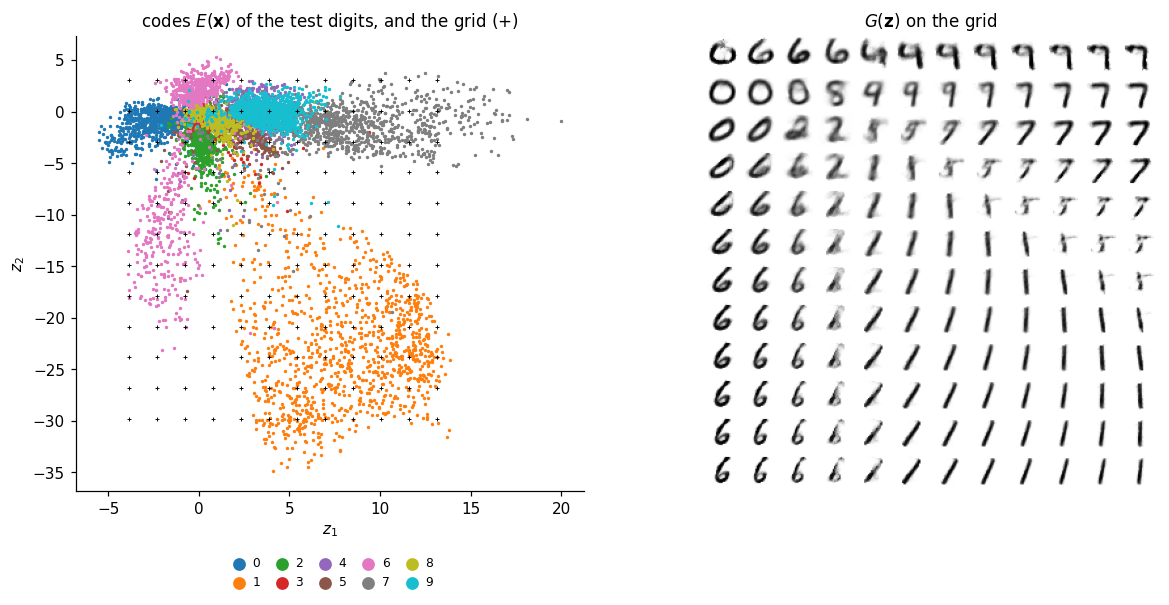

In [5]:
lo, hi = np.percentile(Z_ae2, 1, axis=0), np.percentile(Z_ae2, 99, axis=0)
g1, g2 = np.linspace(lo[0], hi[0], 12), np.linspace(hi[1], lo[1], 12)
z_grid = np.array([[a, b] for b in g2 for a in g1], dtype=np.float32)
imgs_ae_grid = np.asarray(ae_decode(ae2, jnp.asarray(z_grid)))

fig = plt.figure(figsize=(10.5, 4.6))
ax = fig.add_axes([0.0, 0.05, 0.44, 0.9])
for d in range(10):
    m = yte == d
    ax.scatter(Z_ae2[m, 0], Z_ae2[m, 1], s=1.5, color=cmap10(d), label=str(d), rasterized=True)
ax.scatter(z_grid[:, 0], z_grid[:, 1], s=6, marker="+", color="k", lw=0.6)
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$"); ax.set_title("codes $E(\\mathbf{x})$ of the test digits, and the grid (+)")
ax.legend(markerscale=6, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), handletextpad=0.1, columnspacing=0.8)
big = np.ones((12 * 29, 12 * 29))
for k, im in enumerate(imgs_ae_grid):
    r, c = divmod(k, 12)
    big[r * 29:r * 29 + 28, c * 29:c * 29 + 28] = 1 - im.reshape(28, 28)
ax2 = fig.add_axes([0.5, 0.05, 0.48, 0.9])
ax2.imshow(big, cmap="gray", vmin=0, vmax=1); ax2.set_xticks([]); ax2.set_yticks([])
for s in ax2.spines.values(): s.set_visible(False)
ax2.set_title("$G(\\mathbf{z})$ on the grid")
save(fig, "gen_ae_holes.png"); plt.show()

Many grid points decode to digits, but between and around the clusters of codes there are regions that decode to blurred shapes that are no digit, and the codes of different digits have very different spreads. Nothing in the training tells us where the "valid" latent vectors are.

### Random latent vectors in 16 dimensions

With $d=16$ we can no longer look at the latent space, so we sample it instead. We draw random latent vectors in two ways: from $\mathcal N(0,I)$, and from a Gaussian fitted to the training codes coordinate by coordinate, $z_k\sim\mathcal N(m_k,s_k^2)$, where $m_k$ and $s_k$ are the mean and standard deviation of $E(\mathbf x)_k$ over the training set. The printed standard deviations, between about 1.8 and 3.6, already show that the codes do not follow $\mathcal N(0,I)$.

standard deviations of the 16 code coordinates: [3.47 1.99 1.8  2.42 2.34 2.76 2.69 3.33 2.6  2.43 3.3  2.84 3.57 3.05
 2.27 2.66]


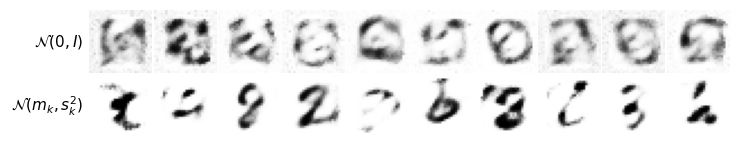

In [6]:
m16, s16 = Z_ae16_tr.mean(0), Z_ae16_tr.std(0)
k1, k2 = jax.random.split(jax.random.key(10))
z_std = jax.random.normal(k1, (2000, 16))
z_fit = m16 + s16 * np.asarray(jax.random.normal(k2, (2000, 16)))
imgs_ae16_std = np.asarray(ae_decode(ae16, z_std))
imgs_ae16_fit = np.asarray(ae_decode(ae16, jnp.asarray(z_fit)))
nums["ae16_code_std_range"] = [float(s16.min()), float(s16.max())]
print("standard deviations of the 16 code coordinates:", np.round(s16, 2))
show_grid(np.concatenate([imgs_ae16_std[:10], imgs_ae16_fit[:10]]), 2, 10, "gen_ae_random16.png", size=0.75,
          row_labels=[r"$\mathcal{N}(0, I)$", r"$\mathcal{N}(m_k, s_k^2)$"], fontsize=10)

Neither choice works. The codes of an autoencoder do not fill a simple region: they lie on a thin, curved set, and a random point of $\mathbb R^{16}$, even one with the right mean and spread in every coordinate, almost never falls on it; Section 5 measures this with a classifier. **To generate we need a latent space whose distribution we know and can sample.** This is what the variational autoencoder adds.

As an exercise, decode the midpoint $\frac12\big(E(\mathbf x_a)+E(\mathbf x_b)\big)$ of the codes of two different test digits with the $d=16$ autoencoder and check whether it is a digit.

<hr/>
## 2. Probability, likelihood, maximum likelihood

A model $p(x\,|\,\theta)$ gives the probability of data $x$ when the parameters are $\theta$. The same formula can be read in two ways. Read as a **probability**, $\theta$ is fixed and $x$ varies; summed over all outcomes $x$ it gives 1. Read as a **likelihood**, the observed data are fixed and $\theta$ varies, $L(\theta)=p(x_{\rm obs}\,|\,\theta)$; this is a function of $\theta$, not a probability distribution over $\theta$, and nothing forces it to integrate to 1.

A coin with probability $\theta$ of heads, tossed 10 times, shows the difference: $p(k\,|\,\theta)=\binom{10}{k}\theta^k(1-\theta)^{10-k}$. We observed $k=7$. The left panel below plots $p(k\,|\,0.5)$ as a distribution over $k$, the right panel $L(\theta)=p(7\,|\,\theta)$ as a function of $\theta$. The printout gives $p(7\,|\,0.5)=0.117$, the maximum of the likelihood at $\theta=0.7$, and $\int_0^1L\,d\theta=1/11$, which confirms that the likelihood is not normalised.

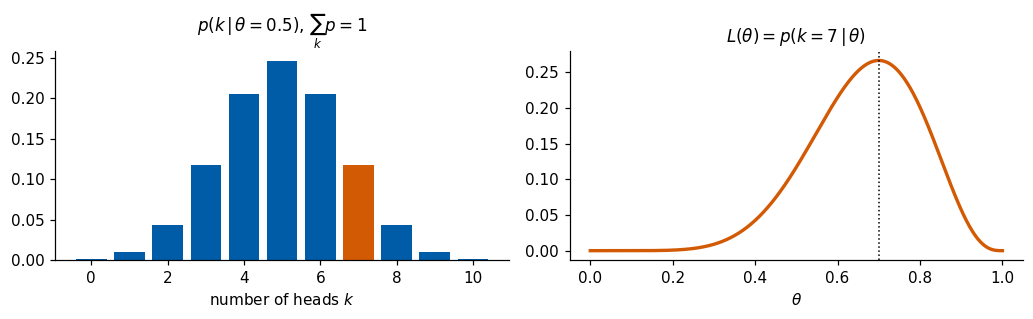

p(7 | 0.5) = 0.117;  argmax L = 0.700;  integral of L over theta = 0.0909 (= 1/11)


In [7]:
ks, th = np.arange(11), np.linspace(0, 1, 401)
p_k = np.array([comb(10, k) * 0.5 ** 10 for k in ks])
L_th = comb(10, 7) * th ** 7 * (1 - th) ** 3
nums["coin_p7_given_half"] = float(p_k[7])
nums["coin_theta_ml"] = float(th[np.argmax(L_th)])
nums["coin_L_integral"] = float(np.trapezoid(L_th, th))
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.0))
axs[0].bar(ks, p_k, color=UJBlue); axs[0].bar([7], [p_k[7]], color=DSOrange)
axs[0].set_xlabel("number of heads $k$"); axs[0].set_title(r"$p(k\,|\,\theta = 0.5)$, $\sum_k p = 1$")
axs[1].plot(th, L_th, color=DSOrange, lw=2.2); axs[1].axvline(0.7, color="k", ls=":", lw=1)
axs[1].set_xlabel(r"$\theta$"); axs[1].set_title(r"$L(\theta) = p(k = 7\,|\,\theta)$")
plt.tight_layout(); save(fig, "gen_prob_vs_likelihood.png"); plt.show()
print(f"p(7 | 0.5) = {nums['coin_p7_given_half']:.3f};  argmax L = {nums['coin_theta_ml']:.3f};  "
      f"integral of L over theta = {nums['coin_L_integral']:.4f} (= 1/11)")

### Maximum likelihood

Given data $\mathbf x_1,\dots,\mathbf x_n$, independent samples of an unknown $p(\mathbf x)$, and a model $p_\theta(\mathbf x)$, the likelihood of all the data and its logarithm are
$$L(\theta)=\prod_{i=1}^n p_\theta(\mathbf x_i),\qquad \ell(\theta)=\sum_{i=1}^n\log p_\theta(\mathbf x_i),\qquad \theta^*=\arg\max_\theta\ell(\theta).$$
For $n\to\infty$, $\frac1n\ell(\theta)\to\mathbb E_{p}[\log p_\theta]=-H(p)-\mathrm{KL}(p\,\|\,p_\theta)$, where $H$ is the entropy and KL the Kullback–Leibler divergence. Since $H(p)$ does not depend on $\theta$, maximum likelihood minimises the KL divergence between the data distribution and the model. The cross-entropy loss of classification is minus a log-likelihood of exactly this kind.

As an example we take 1500 points in 2D drawn from three groups and fit two models. The first is one Gaussian, for which $\theta^*$ is known in closed form: the sample mean and the sample covariance (with $1/n$). The second is a mixture of three Gaussians,
$$p_\theta(\mathbf x)=\sum_{k=1}^{3}\pi_k\,\mathcal N(\mathbf x;\boldsymbol\mu_k,\Sigma_k),$$
which has no closed-form maximum. We therefore maximise $\ell$ by **gradient ascent**, exactly as we train a network. The constraints on the parameters are built into the parametrisation: $\pi=\mathrm{softmax}(\mathbf a)$ is automatically a probability vector, and $\Sigma_k=L_kL_k^\top$ with $L_k$ lower-triangular and a positive diagonal $e^{(\cdot)}$ is automatically positive definite. Fitting the single Gaussian by the same gradient ascent tests the procedure against the closed form. Finally we **draw new points** from each fitted model and compare them with the data.

one Gaussian: gradient ascent mean [ 0.579 -0.061] | sample mean [ 0.579 -0.061]
              gradient ascent cov  [[7.144000053405762, -0.6740000247955322], [-0.6740000247955322, 5.1579999923706055]] | sample cov (1/n) [[7.144, -0.674], [-0.674, 5.158]]
mean log-likelihood per point: one Gaussian -4.635, mixture of three -3.679


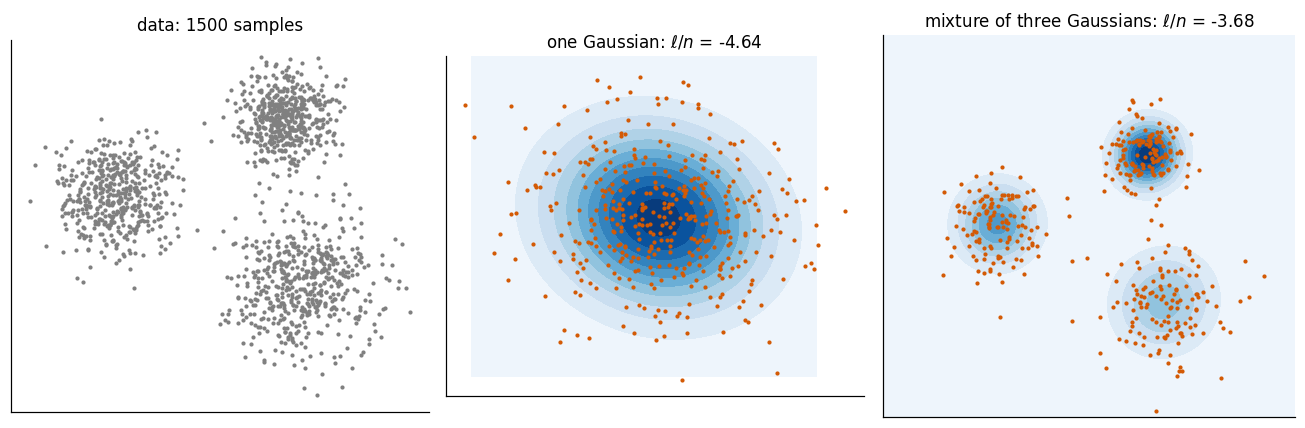

In [8]:
rng = np.random.default_rng(0)
centres, widths = np.array([[-3, 0], [2, 2.5], [2.5, -2.5]]), np.array([0.9, 0.7, 1.1])
lab = rng.integers(0, 3, 1500)
X2 = (centres[lab] + widths[lab, None] * rng.normal(size=(1500, 2))).astype(np.float32)

def gauss_logpdf(x, mu, Lraw):
    """log N(x; mu, L L^T), L lower-triangular with exp on the diagonal."""
    L = jnp.tril(Lraw, -1) + jnp.diag(jnp.exp(jnp.diag(Lraw)))
    u = jax.scipy.linalg.solve_triangular(L, (x - mu).T, lower=True)          # L^{-1} (x - mu)
    return -0.5 * jnp.sum(u ** 2, 0) - jnp.sum(jnp.diag(Lraw)) - jnp.log(2 * jnp.pi)

def mixture_loglik(theta, x):          # log p(x) for every point
    comp = jax.vmap(lambda mu, Lr: gauss_logpdf(x, mu, Lr))(theta["mu"], theta["L"])   # (K, n)
    return jax.scipy.special.logsumexp(jax.nn.log_softmax(theta["a"])[:, None] + comp, axis=0)

def fit_mixture(x, K, steps=3000, lr=0.05):
    first = x[0]; idx = [int(np.argmax(((x - first) ** 2).sum(1)))]     # farthest-point initial means
    while len(idx) < K:
        idx.append(int(np.argmax(np.min([((x - x[j]) ** 2).sum(1) for j in idx], 0))))
    theta = {"a": jnp.zeros(K), "mu": jnp.asarray(x[idx]), "L": jnp.zeros((K, 2, 2))}
    tx = optax.adam(lr); st = tx.init(theta); xj = jnp.asarray(x)
    @jax.jit
    def run(theta, st):
        def step(c, _):
            theta, st = c
            nll, g = jax.value_and_grad(lambda t: -mixture_loglik(t, xj).mean())(theta)
            up, st = tx.update(g, st, theta)
            return (optax.apply_updates(theta, up), st), nll
        return jax.lax.scan(step, (theta, st), None, length=steps)
    (theta, _), nll = run(theta, st)
    return theta, np.asarray(nll)

def sample_mixture(theta, key, n):
    kc, kz = jax.random.split(key)
    c = jax.random.categorical(kc, theta["a"], shape=(n,))
    L = jnp.tril(theta["L"], -1) + jax.vmap(jnp.diag)(jnp.exp(jax.vmap(jnp.diag)(theta["L"])))
    return np.asarray(theta["mu"][c] + jnp.einsum("nij,nj->ni", L[c], jax.random.normal(kz, (n, 2))))

theta1, nll1 = fit_mixture(X2, 1)
theta3, nll3 = fit_mixture(X2, 3)
mean_ml, cov_ml = X2.mean(0), np.cov(X2.T, bias=True)
L1 = np.tril(np.asarray(theta1["L"][0]), -1) + np.diag(np.exp(np.diag(np.asarray(theta1["L"][0]))))
print("one Gaussian: gradient ascent mean", np.round(np.asarray(theta1["mu"][0]), 3), "| sample mean", np.round(mean_ml, 3))
print("              gradient ascent cov ", np.round(L1 @ L1.T, 3).tolist(), "| sample cov (1/n)", np.round(cov_ml, 3).tolist())
nums["mle_loglik_1"], nums["mle_loglik_3"] = float(-nll1[-1]), float(-nll3[-1])
print(f"mean log-likelihood per point: one Gaussian {nums['mle_loglik_1']:.3f}, mixture of three {nums['mle_loglik_3']:.3f}")

xx, yy = np.meshgrid(np.linspace(-7, 7, 200), np.linspace(-6.5, 6.5, 200))
grid2 = jnp.asarray(np.c_[xx.ravel(), yy.ravel()], dtype=jnp.float32)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
axs[0].scatter(X2[:, 0], X2[:, 1], s=3, color="grey"); axs[0].set_title("data: 1500 samples")
for a, theta, name, key in [(axs[1], theta1, "one Gaussian", 1), (axs[2], theta3, "mixture of three Gaussians", 2)]:
    dens = np.exp(np.asarray(mixture_loglik(theta, grid2))).reshape(xx.shape)
    a.contourf(xx, yy, dens, levels=12, cmap="Blues")
    new = sample_mixture(theta, jax.random.key(key), 400)
    a.scatter(new[:, 0], new[:, 1], s=3, color=DSOrange)
    a.set_title(f"{name}: " + r"$\ell/n$" + f" = {float(mixture_loglik(theta, jnp.asarray(X2)).mean()):.2f}")
for a in axs: a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
plt.tight_layout(); save(fig, "gen_mle_gmm.png"); plt.show()

Gradient ascent reproduces the closed-form mean and covariance of the single Gaussian. The mixture assigns the data a higher likelihood, $-3.679$ against $-4.635$ per point, and its samples (orange) look like the data, while the single Gaussian puts probability where there are no data. For images no closed formula of this kind exists: a neural network must represent $p_\theta(\mathbf x)$.

As an exercise, fit mixtures with $K=2,3,6,12$ components and evaluate $\ell/n$ on the training points and on 1500 fresh points from the same three groups. Find the $K$ at which a larger model stops helping.

<hr/>
## 3. The variational autoencoder

### 3.1 Latent-variable models and the marginal likelihood

We want a model $p_\theta(\mathbf x)$ that we can **sample**, and the simplest way to guarantee this is to build it in two stages. First a latent vector is drawn from a fixed, simple **prior**, $\mathbf z\sim p(\mathbf z)=\mathcal N(0,I_d)$. Then a neural network, the **decoder** $G_\theta:\mathbb R^d\to\mathbb R^{784}$, turns it into a distribution over images. For pixels in $[0,1]$ we use independent Bernoulli pixels with probabilities $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$, where $\sigma$ is the logistic sigmoid applied to each of the 784 outputs:
$$p_\theta(\mathbf x|\mathbf z)=\prod_{j=1}^{784}\hat x_j^{\,x_j}(1-\hat x_j)^{1-x_j},\qquad -\log p_\theta(\mathbf x|\mathbf z)=\underbrace{-\sum_{j=1}^{784}\big[x_j\log\hat x_j+(1-x_j)\log(1-\hat x_j)\big]}_{\mathrm{BCE}(\mathbf x,\hat{\mathbf x})}.$$
The negative log-probability is the binary cross-entropy (BCE). MNIST pixels are grey values, not 0/1, but the BCE is still a valid loss and is the standard choice.

Sampling from this model is easy: draw $\mathbf z$, decode. Training it by maximum likelihood is not, because the likelihood of an image is the **marginal**
$$\log p_\theta(\mathbf x)=\log\int p_\theta(\mathbf x|\mathbf z)\,p(\mathbf z)\,d\mathbf z .$$
This integral over $\mathbb R^d$ has no closed form, and estimating it by sampling $\mathbf z$ from the prior fails in practice: for a given image only a tiny region of latent space produces it, so almost all prior samples contribute nothing (Section 3.8 measures this). We cannot maximise $\log p_\theta(\mathbf x)$ directly, and the next subsection replaces it by a quantity we can compute.

### 3.2 The evidence lower bound (ELBO)

The derivation uses four standard facts, which we recall first. The *expectation* of $f$ over a distribution $q$ is $\mathbb E_{q}[f]=\int q(\mathbf z)\,f(\mathbf z)\,d\mathbf z$, and it can be estimated by sampling, $\mathbb E_q[f]\approx\frac1M\sum_m f(\mathbf z_m)$ with $\mathbf z_m\sim q$. The *Gaussian density* in one dimension is $\mathcal N(z;\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}e^{-(z-\mu)^2/2\sigma^2}$, and a diagonal Gaussian in $d$ dimensions is the product of $d$ of them. *Bayes' rule* states $p(\mathbf x,\mathbf z)=p(\mathbf x|\mathbf z)p(\mathbf z)=p(\mathbf z|\mathbf x)p(\mathbf x)$. Finally, the *Kullback–Leibler divergence* $\mathrm{KL}(q\,\|\,p)=\mathbb E_q\big[\log\frac{q}{p}\big]$ is $\ge0$, with equality only for $q=p$. The proof uses *Jensen's inequality* for the concave logarithm, $\mathbb E[\log Y]\le\log\mathbb E[Y]$:
$$-\mathrm{KL}(q\|p)=\mathbb E_q\Big[\log\frac pq\Big]\le\log\mathbb E_q\Big[\frac pq\Big]=\log\int p\,d\mathbf z=\log1=0 .$$

The new ingredient is an **encoder**: a second network that proposes, for each image, the latent vectors that could have produced it,
$$q_\phi(\mathbf z|\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\,\mathrm{diag}\,\boldsymbol\sigma_\phi^2(\mathbf x)\big),$$
a Gaussian whose $d$ means and $d$ variances are all outputs of the network.

We start from Bayes' rule. For every $\mathbf z$ it gives $p_\theta(\mathbf x)=p_\theta(\mathbf x|\mathbf z)\,p(\mathbf z)/p_\theta(\mathbf z|\mathbf x)$, where $p_\theta(\mathbf z|\mathbf x)$ is the true posterior. Taking the logarithm, and multiplying and dividing by $q_\phi(\mathbf z|\mathbf x)$ inside it, we obtain
$$\log p_\theta(\mathbf x)=\log p_\theta(\mathbf x|\mathbf z)-\log\frac{q_\phi(\mathbf z|\mathbf x)}{p(\mathbf z)}+\log\frac{q_\phi(\mathbf z|\mathbf x)}{p_\theta(\mathbf z|\mathbf x)} .$$

This identity holds for every $\mathbf z$, so it also holds on average over $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$. The left-hand side does not depend on $\mathbf z$ and is unchanged by the average. On the right, the averages of the last two terms are Kullback–Leibler divergences, $\mathrm{KL}(q\|p)=\mathbb E_q[\log q/p]$, which gives
$$\log p_\theta(\mathbf x)=\underbrace{\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[\log p_\theta(\mathbf x|\mathbf z)\big]-\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)}_{\mathrm{ELBO}(\theta,\phi;\,\mathbf x)}\;+\;\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p_\theta(\mathbf z|\mathbf x)\big).$$

The last term is a KL divergence and therefore never negative (Gibbs' inequality, proved above), so dropping it gives the bound
$$\log p_\theta(\mathbf x)\ \ge\ \mathrm{ELBO}(\theta,\phi;\mathbf x),$$
the **E**vidence **L**ower **BO**und, where "evidence" is the name for $p_\theta(\mathbf x)$. The gap is $\mathrm{KL}(q_\phi\,\|\,p_\theta(\mathbf z|\mathbf x))$, so the bound is tight when the encoder equals the true posterior. Maximising the ELBO over $\theta$ and $\phi$ therefore does two things at once: it pushes $\log p_\theta(\mathbf x)$ up (approximate maximum likelihood) and it pushes $q_\phi$ towards the true posterior. Unlike $\log p_\theta(\mathbf x)$, everything in the ELBO is computable: an average over a Gaussian we can sample, and a KL divergence between two Gaussians.

Each of the two terms has a clear role. The first, $\mathbb E_q[\log p_\theta(\mathbf x|\mathbf z)]=-\mathbb E_q\,\mathrm{BCE}(\mathbf x,\hat{\mathbf x})$, is the **reconstruction** term: latent vectors drawn from the encoder's cloud must decode back to $\mathbf x$. On its own it would shrink each cloud to a point and move the clouds apart, which is an ordinary autoencoder. The second, $-\mathrm{KL}(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z))$, keeps the encoder **close to the prior**: every cloud is pulled towards $\mathcal N(0,I)$. The clouds of all images then overlap and fill the prior without holes, and this is what makes a fresh $\mathbf z\sim\mathcal N(0,I)$ decode to a valid image.

Physicists know the ELBO under another name, the variational free energy. In statistical mechanics, a system with states $\mathbf z$ of energy $E(\mathbf z)$ at temperature $T$ is in the Boltzmann distribution $e^{-E(\mathbf z)/T}/Z$, with partition function $Z=\int e^{-E/T}d\mathbf z$ and free energy $F=-T\log Z$. For any trial distribution $q$ one defines $F[q]=\langle E\rangle_q-T\,S[q]$, with the entropy $S[q]=-\mathbb E_q\log q$; it is smallest, and equal to $F$, for the Boltzmann distribution. Now define an "energy" of the latent configuration $\mathbf z$ for a fixed image, $E(\mathbf z)=-\log\big[p_\theta(\mathbf x|\mathbf z)p(\mathbf z)\big]$, at temperature $T=1$. Its Boltzmann distribution is the posterior, $e^{-E(\mathbf z)}/Z=p_\theta(\mathbf z|\mathbf x)$, with partition function $Z=\int e^{-E}d\mathbf z=p_\theta(\mathbf x)$ and free energy $F=-\log Z=-\log p_\theta(\mathbf x)$. For a trial distribution $q$, the variational free energy is
$$F[q]=\langle E\rangle_q-S[q],\qquad S[q]=-\mathbb E_q\log q ,$$
and inserting $E=-\log Z-\log(e^{-E}/Z)$ into $\langle E\rangle_q$ gives $F[q]=F+\mathrm{KL}(q\,\|\,e^{-E}/Z)\ge F$, the **Gibbs–Bogoliubov** inequality behind mean-field theory. Comparing with the ELBO, $F[q]=-\mathrm{ELBO}$. Training a VAE is minimising a variational free energy, with a Gaussian trial distribution produced by a network for each image.

### 3.3 The VAE loss

Per image we minimise $-\mathrm{ELBO}$. Using one sample of $\mathbf z$ per image (Section 3.5) and the closed-form KL divergence (Section 3.4), the loss is
$$\mathcal L(\mathbf x)=\mathrm{BCE}\big(\mathbf x,\sigma(G_\theta(\mathbf z))\big)+\tfrac12\sum_{k=1}^{d}\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big),\qquad\mathbf z\sim q_\phi(\mathbf z|\mathbf x),$$
averaged over a minibatch and measured in nats per image.

References: D. P. Kingma, M. Welling, *Auto-Encoding Variational Bayes*, ICLR 2014, [arXiv:1312.6114](https://arxiv.org/abs/1312.6114); D. J. Rezende, S. Mohamed, D. Wierstra, *Stochastic Backpropagation and Approximate Inference in Deep Generative Models*, ICML 2014, [PMLR 32, 1278](https://proceedings.mlr.press/v32/rezende14.html); review: D. P. Kingma, M. Welling, *An Introduction to Variational Autoencoders*, Found. Trends Mach. Learn. **12**, 307 (2019), [doi:10.1561/2200000056](https://doi.org/10.1561/2200000056).

### 3.4 KL divergence between two Gaussians

The KL term of the loss can be computed exactly. For one latent coordinate, with $q=\mathcal N(\mu,\sigma^2)$ and $p=\mathcal N(0,1)$,
$$\log q(z)=-\tfrac12\log(2\pi\sigma^2)-\frac{(z-\mu)^2}{2\sigma^2},\qquad \log p(z)=-\tfrac12\log(2\pi)-\frac{z^2}{2}.$$
Averaging the difference over $z\sim q$ and using $\mathbb E_q[(z-\mu)^2]=\sigma^2$ and $\mathbb E_q[z^2]=\mu^2+\sigma^2$ gives
$$\mathrm{KL}(q\,\|\,p)=\mathbb E_q[\log q-\log p]=-\tfrac12\log\sigma^2-\tfrac12+\tfrac12(\mu^2+\sigma^2)=\tfrac12\big(\mu^2+\sigma^2-\ln\sigma^2-1\big).$$
For a diagonal Gaussian in $d$ dimensions, $\log q$ and $\log p$ are sums over coordinates, so the KL divergence is the sum of $d$ such terms. It is zero only for $\mu=0$, $\sigma=1$. The encoder outputs $\log\sigma^2$ rather than $\sigma$, because any real number is then allowed and $\sigma^2=e^{\log\sigma^2}>0$ holds automatically.

To make sure the formula and its implementation are right, the next cell compares the closed form with a Monte Carlo estimate $\frac1M\sum_m[\log q(z_m)-\log p(z_m)]$ using $M=10^6$ samples $z_m\sim q$, for three choices of $(\mu,\sigma)$. The two agree to within the Monte Carlo error, a few thousandths of a nat.

In [9]:
def kl_per_dim(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) for every latent coordinate; sigma^2 = exp(logvar). Same shape as mu."""
    return 0.5 * (mu ** 2 + jnp.exp(logvar) - logvar - 1)

def log_normal(z, mu, logvar):
    """log N(z; mu, sigma^2), elementwise."""
    return -0.5 * (jnp.log(2 * jnp.pi) + logvar + (z - mu) ** 2 / jnp.exp(logvar))

for mu_t, sigma_t in [(0.0, 1.0), (1.5, 0.5), (-0.3, 2.0)]:
    z = mu_t + sigma_t * jax.random.normal(jax.random.key(0), (1_000_000,))          # samples of q
    lv = jnp.log(sigma_t ** 2)
    kl_mc = jnp.mean(log_normal(z, mu_t, lv) - log_normal(z, 0.0, 0.0))
    kl_cf = kl_per_dim(jnp.asarray(mu_t), lv)
    print(f"mu = {mu_t:5.2f}, sigma = {sigma_t:4.2f}:   KL closed form = {float(kl_cf):.4f}   KL Monte Carlo = {float(kl_mc):.4f}")
    assert abs(float(kl_cf) - float(kl_mc)) < 5e-3

mu =  0.00, sigma = 1.00:   KL closed form = 0.0000   KL Monte Carlo = 0.0000
mu =  1.50, sigma = 0.50:   KL closed form = 1.4431   KL Monte Carlo = 1.4441
mu = -0.30, sigma = 2.00:   KL closed form = 0.8519   KL Monte Carlo = 0.8484


### 3.5 The reparametrisation trick

The reconstruction term is an average over $q_\phi$, and we estimate it with **one** sample $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$ per image; the average over the minibatch and over training steps does the rest. The loss then depends on $\phi$ through a *random draw*, and this creates a problem for training. A sampling routine is not a differentiable function of $\boldsymbol\mu,\boldsymbol\sigma$: if we draw $\mathbf z$ and then change $\boldsymbol\mu$ slightly, there is no rule that says how this particular $\mathbf z$ should move, so backpropagation cannot pass from the decoder into the encoder.

The solution is to write the same random variable as a **deterministic function** of the parameters and of a parameter-free noise,
$$\mathbf z=\boldsymbol\mu_\phi(\mathbf x)+\boldsymbol\sigma_\phi(\mathbf x)\odot\boldsymbol\varepsilon,\qquad\boldsymbol\varepsilon\sim\mathcal N(0,I),\qquad\boldsymbol\sigma=e^{\frac12\log\boldsymbol\sigma^2}.$$
This $\mathbf z$ has exactly the distribution $\mathcal N(\boldsymbol\mu,\mathrm{diag}\,\boldsymbol\sigma^2)$, but now $\partial z_k/\partial\mu_k=1$ and $\partial z_k/\partial\sigma_k=\varepsilon_k$, and for any function $f$
$$\nabla_{\mu,\sigma}\,\mathbb E_{\mathbf z\sim q}[f(\mathbf z)]=\mathbb E_{\boldsymbol\varepsilon}\big[\nabla_{\mu,\sigma}f(\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon)\big],$$
an average of ordinary gradients that backpropagation computes. In JAX, $\boldsymbol\varepsilon$ is drawn from an explicit key, `jax.random.normal(key, mu.shape)`, and `jax.grad` differentiates through $\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$.

We test the trick on a case with a known answer. For $f(z)=z^2$, $\mathbb E_q[z^2]=\mu^2+\sigma^2$, so $\partial/\partial\mu=2\mu$ and $\partial/\partial\sigma=2\sigma$. The next cell applies `jax.grad` to the reparametrised Monte Carlo average and compares the result with these exact derivatives; with $2\times10^5$ samples they agree to better than one percent.

In [10]:
def mc_average_of_z2(params, key, n_samples=200_000):
    """(1/M) sum_m f(mu + sigma * eps_m) with f(z) = z^2; differentiable in (mu, sigma)."""
    mu, sigma = params
    eps = jax.random.normal(key, (n_samples,))        # parameter-free noise
    z = mu + sigma * eps                              # reparametrised sample of N(mu, sigma^2)
    return jnp.mean(z ** 2)

mu_t, sigma_t = 0.7, 1.3
g_mu, g_sigma = jax.grad(mc_average_of_z2)((mu_t, sigma_t), jax.random.key(1))
print(f"d/dmu    E[z^2]:  reparametrisation {float(g_mu):.4f}   exact 2 mu    = {2 * mu_t:.4f}")
print(f"d/dsigma E[z^2]:  reparametrisation {float(g_sigma):.4f}   exact 2 sigma = {2 * sigma_t:.4f}")
assert abs(float(g_mu) - 2 * mu_t) < 0.02 and abs(float(g_sigma) - 2 * sigma_t) < 0.02

d/dmu    E[z^2]:  reparametrisation 1.4060   exact 2 mu    = 1.4000
d/dsigma E[z^2]:  reparametrisation 2.5935   exact 2 sigma = 2.6000


### 3.6 The network and the loss

The table lists the shapes for a minibatch of $B$ images, latent dimension $d$ and an optional condition with $C$ numbers. The condition is used only in Section 6; here $C=0$.

| quantity | shape | layer |
|---|---|---|
| input $\mathbf x$ (and condition $\mathbf c$) | $(B,784)$ (and $(B,C)$) | |
| encoder hidden layers | $(B,400)\to(B,200)$ | dense + ReLU on $[\mathbf x,\mathbf c]$ |
| $\boldsymbol\mu$, $\log\boldsymbol\sigma^2$ | $(B,d)$ each | two separate linear heads |
| $\boldsymbol\varepsilon$, $\mathbf z$ | $(B,d)$ | $\mathbf z=\boldsymbol\mu+e^{\frac12\log\boldsymbol\sigma^2}\odot\boldsymbol\varepsilon$ |
| decoder hidden layers | $(B,200)\to(B,400)$ | dense + ReLU on $[\mathbf z,\mathbf c]$ |
| logits $G_\theta(\mathbf z)$ | $(B,784)$ | linear |

The decoder returns **logits**, not probabilities, because `optax.sigmoid_binary_cross_entropy(logits, x)` computes the BCE from the logits in a numerically stable way, with no $\log 0$ when a sigmoid saturates. The sigmoid is applied only when we want to look at the images.

The `VAE` class takes an optional condition `cond` (the number $C$ of extra inputs), so that the conditional VAE of Section 6 is the same class. As a first sanity check, the loss of the untrained network is dominated by the reconstruction term, about 568 nats per image, while the KL term is close to zero.

In [11]:
class VAE(nnx.Module):
    """Dense (conditional) VAE.
    encoder: [x, c] (B, 784 + C) -> 400 -> 200 -> mu (B, d), logvar (B, d)
    decoder: [z, c] (B, d + C)   -> 200 -> 400 -> pixel logits (B, 784)"""
    def __init__(self, d, cond=0, D=784, hidden=(400, 200), *, rngs):
        h1, h2 = hidden
        self.d, self.cond = d, cond
        self.enc = nnx.List([nnx.Linear(D + cond, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs)])
        self.mu = nnx.Linear(h2, d, rngs=rngs)              # head 1: the means
        self.logvar = nnx.Linear(h2, d, rngs=rngs)          # head 2: log sigma^2, any real number
        self.dec = nnx.List([nnx.Linear(d + cond, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs), nnx.Linear(h1, D, rngs=rngs)])

    def encode(self, x, c=None):
        """q_phi(z | x [, c]): returns (mu, logvar), each (B, d)."""
        h = x if c is None else jnp.concatenate([x, c], axis=-1)     # (B, 784 + C)
        for layer in self.enc:
            h = nnx.relu(layer(h))
        return self.mu(h), self.logvar(h)

    def decode(self, z, c=None):
        """G_theta(z [, c]): pixel logits (B, 784); sigmoid(logits) are the Bernoulli probabilities."""
        h = z if c is None else jnp.concatenate([z, c], axis=-1)     # (B, d + C)
        for layer in self.dec[:-1]:
            h = nnx.relu(layer(h))
        return self.dec[-1](h)

def reparametrise(mu, logvar, key):
    """z = mu + sigma * eps, eps ~ N(0, I); the only random step of the VAE."""
    eps = jax.random.normal(key, mu.shape)
    return mu + jnp.exp(0.5 * logvar) * eps

def vae_loss(model, batch, key):
    """-ELBO per image, averaged over the minibatch. batch = (x,) for the VAE, (x, c) for the cVAE."""
    x, c = batch if len(batch) == 2 else (batch[0], None)
    mu, logvar = model.encode(x, c)                                     # (B, d), (B, d)
    z = reparametrise(mu, logvar, key)                                  # (B, d): one sample per image
    rec = optax.sigmoid_binary_cross_entropy(model.decode(z, c), x).sum(axis=-1).mean()   # sum over pixels, mean over images
    kl = kl_per_dim(mu, logvar).sum(axis=-1).mean()                     # sum over latent coordinates, mean over images
    return rec + kl, {"loss": rec + kl, "rec": rec, "kl": kl}

# shape checks on a minibatch of 5 images
_m = VAE(16, rngs=nnx.Rngs(0))
_mu, _lv = _m.encode(Xtr_d[:5])
assert _mu.shape == _lv.shape == (5, 16)
assert _m.decode(reparametrise(_mu, _lv, jax.random.key(0))).shape == (5, 784)
print("parameters of the VAE (d = 16):", sum(p.size for p in jax.tree_util.tree_leaves(nnx.state(_m, nnx.Param))))
print("loss of the untrained VAE (nats per image):", {k: round(float(v), 1) for k, v in vae_loss(_m, (Xtr_d[:256],), jax.random.key(0))[1].items()})

vae_enc = nnx.jit(lambda m, x: m.encode(x))                    # (mu, logvar)
vae_dec = nnx.jit(lambda m, z: jax.nn.sigmoid(m.decode(z)))    # pixel probabilities in (0, 1)

parameters of the VAE (d = 16): 798816


loss of the untrained VAE (nats per image): {'loss': 567.8, 'rec': 567.6, 'kl': 0.2}


### 3.7 Training

We train two VAEs on the 60 000 training digits, **without labels**: one with $d=2$, whose latent plane we can draw, and one with $d=16$ (Adam, learning rate $10^{-3}$, minibatches of 128; 15 and 20 epochs). The printed numbers are per image, in nats: the loss $-\mathrm{ELBO}$, the reconstruction term and the KL term. The KL term grows during training (from 4.8 to 6.6 nats for $d=2$, from 13.3 to 22.8 nats for $d=16$) while the reconstruction term falls: the encoder moves away from the prior to the extent that better reconstructions pay for it.

VAE, d = 2


  epoch   1: kl 4.8245  loss 186.1100  rec 181.2855   (  7.0 s)


  epoch   5: kl 6.1035  loss 148.7506  rec 142.6471   ( 26.2 s)


  epoch  10: kl 6.4146  loss 143.8450  rec 137.4304   ( 49.8 s)


  epoch  15: kl 6.5959  loss 141.1574  rec 134.5616   ( 73.5 s)
VAE, d = 16


...

  epoch  10: kl 22.5180  loss 103.6880  rec 81.1701   ( 50.8 s)


  epoch  15: kl 22.7050  loss 101.8022  rec 79.0973   ( 74.7 s)


  epoch  20: kl 22.8031  loss 100.6891  rec 77.8860   ( 99.1 s)


vae2 test, per image: {'kl': 6.7, 'loss': 141.9, 'rec': 135.2}


vae16 test, per image: {'kl': 22.7, 'loss': 101.0, 'rec': 78.3}


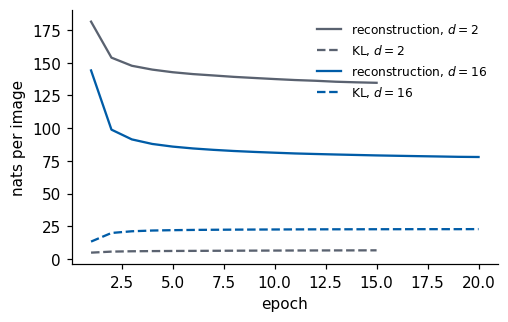

In [12]:
EPOCHS_VAE = 20
t0 = time.time()
print("VAE, d = 2");  vae2, h_vae2 = train(VAE(2, rngs=nnx.Rngs(2)), vae_loss, (Xtr_d,), epochs=15, seed=2)
print("VAE, d = 16"); vae16, h_vae16 = train(VAE(16, rngs=nnx.Rngs(3)), vae_loss, (Xtr_d,), epochs=EPOCHS_VAE, seed=3)
nums["vae_train_seconds"] = time.time() - t0

def test_elbo_terms(model, key=jax.random.key(4)):
    """Loss, reconstruction and KL per test image (one sample of z per image)."""
    _, aux = nnx.jit(vae_loss)(model, (Xte_d,), key)
    return {k: float(v) for k, v in aux.items()}
for name, m in [("vae2", vae2), ("vae16", vae16)]:
    nums[f"{name}_test"] = test_elbo_terms(m)
    print(name, "test, per image:", {k: round(v, 1) for k, v in nums[f"{name}_test"].items()})

fig, ax = plt.subplots(figsize=(5, 3))
for h, lab, col in [(h_vae2, "$d=2$", UJGray), (h_vae16, "$d=16$", UJBlue)]:
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["rec"], "-", color=col, label=f"reconstruction, {lab}")
    ax.plot(ep, h["kl"], "--", color=col, label=f"KL, {lab}")
ax.set_xlabel("epoch"); ax.set_ylabel("nats per image"); ax.legend(fontsize=8); plt.show()

# one test digit and its VAE reconstruction, for the diagrams of the slides
mu0, _ = vae_enc(vae16, Xte_d[:1])
for arr, name in [(Xte[0], "gen_vae_in.png"), (np.asarray(vae_dec(vae16, mu0))[0], "gen_vae_out.png")]:
    fig = plt.figure(figsize=(2, 2)); plt.imshow(arr.reshape(28, 28), cmap="gray_r"); plt.axis("off")
    save(fig, name, pad_inches=0.02); plt.close(fig)

### 3.8 Tightness of the bound

The ELBO is only a lower bound, so we ask how far it lies below $\log p_\theta(\mathbf x)$ itself. For 200 test images we estimate $\log p_\theta(\mathbf x)$ in two ways, each with $K=1000$ samples. The naive estimate samples the prior, $\log p_\theta(\mathbf x)\approx\log\frac1K\sum_{k}p_\theta(\mathbf x|\mathbf z_k)$ with $\mathbf z_k\sim\mathcal N(0,I)$. The second estimate uses **importance sampling** with the encoder as proposal, $\log p_\theta(\mathbf x)\approx\log\frac1K\sum_k\frac{p_\theta(\mathbf x|\mathbf z_k)\,p(\mathbf z_k)}{q_\phi(\mathbf z_k|\mathbf x)}$ with $\mathbf z_k\sim q_\phi(\mathbf z|\mathbf x)$.

Both sums are unbiased estimates of $p_\theta(\mathbf x)$; their logarithms are lower bounds that tighten as $K$ grows, and for $K=1$ the expectation of the second one is the ELBO [Y. Burda, R. Grosse, R. Salakhutdinov, *Importance Weighted Autoencoders*, [arXiv:1509.00519](https://arxiv.org/abs/1509.00519)]. The sums are computed with `logsumexp`, because the individual $p_\theta(\mathbf x|\mathbf z)$ are as small as $e^{-100}$.

In [13]:
def log_px_estimates(model, X, key, K=1000):
    """Per image: (ELBO with one z, importance-sampling estimate, naive prior-sampling estimate), all in nats."""
    def one_image(x, key):
        k1, k2, k3 = jax.random.split(key, 3)
        mu, lv = model.encode(x[None])                                    # (1, d)
        z_q = mu + jnp.exp(0.5 * lv) * jax.random.normal(k1, (K, mu.shape[1]))   # (K, d) from q(z|x)
        z_p = jax.random.normal(k2, (K, mu.shape[1]))                     # (K, d) from the prior
        log_lik = lambda z: -optax.sigmoid_binary_cross_entropy(model.decode(z), x[None]).sum(-1)   # log p(x|z), (K,)
        log_prior = lambda z: log_normal(z, 0.0, 0.0).sum(-1)
        log_q = log_normal(z_q, mu, lv).sum(-1)
        log_w = log_lik(z_q) + log_prior(z_q) - log_q                     # log importance weights, (K,)
        is_est = jax.scipy.special.logsumexp(log_w) - jnp.log(K)
        naive = jax.scipy.special.logsumexp(log_lik(z_p)) - jnp.log(K)
        elbo = log_lik(reparametrise(mu, lv, k3)).sum() - kl_per_dim(mu, lv).sum()
        return elbo, is_est, naive
    return jax.vmap(one_image)(X, jax.random.split(key, X.shape[0]))

est = nnx.jit(log_px_estimates, static_argnames="K")
parts = [est(vae16, Xte_d[i:i + 20], jax.random.key(30 + i)) for i in range(0, 200, 20)]
elbo_i, is_i, naive_i = [np.concatenate([np.asarray(p[j]) for p in parts]) for j in range(3)]
nums["vae16_bound"] = {"elbo": float(elbo_i.mean()), "log_px_importance": float(is_i.mean()), "log_px_naive": float(naive_i.mean())}
print(f"mean over 200 test images (nats):  ELBO {elbo_i.mean():8.1f}   importance sampling {is_i.mean():8.1f}   naive prior sampling {naive_i.mean():8.1f}")
print(f"gap log p(x) - ELBO, averaged: {np.mean(is_i - elbo_i):.1f} nats")

mean over 200 test images (nats):  ELBO    -98.1   importance sampling    -93.3   naive prior sampling   -154.8
gap log p(x) - ELBO, averaged: 4.8 nats


The importance-sampling estimate, $-93.3$ nats, lies 4.8 nats above the ELBO of $-98.1$ nats: the bound is close to tight. Naive prior sampling gives $-154.8$ nats, a far lower number, although it estimates the same quantity: with $K=1000$ prior samples, almost none lands where $p_\theta(\mathbf x|\mathbf z)$ is large. This is the reason the encoder is needed.

<hr/>
## 4. The latent space of a VAE

### The latent plane of an autoencoder and of a VAE

We first compare the two-dimensional latent spaces directly. The left panel shows the codes $E(\mathbf x)$ of the autoencoder with $d=2$ from Section 1. The right panel shows the means $\boldsymbol\mu_\phi(\mathbf x)$ of the VAE with $d=2$ for the same test digits, together with the circles $|\mathbf z|=1,2,3$ of the prior $\mathcal N(0,I)$. Colours mark the true digits and are used only for plotting.

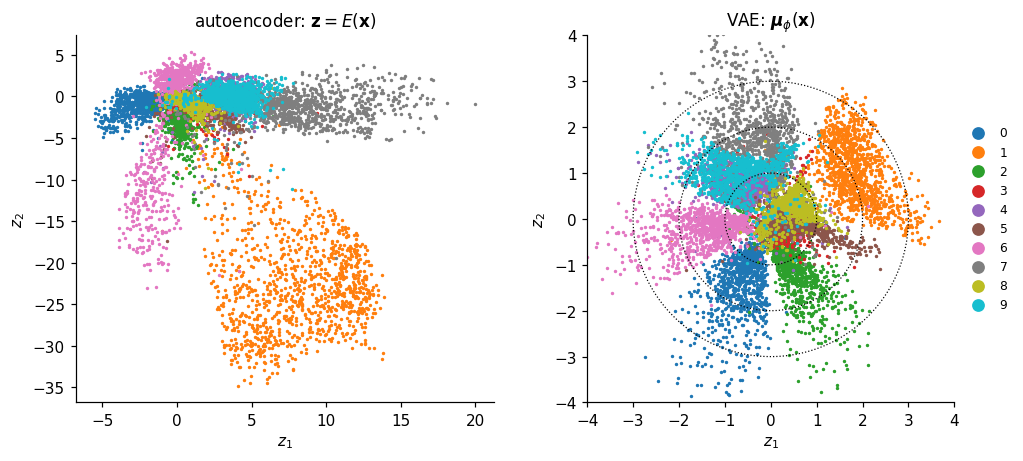

standard deviation of the latent coordinates: AE [3.81 7.46] | VAE means [1.03 1.09]


In [14]:
mu2_te = in_chunks(lambda x: vae_enc(vae2, x)[0], Xte_d)
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.3))
for a, Z, title in [(axs[0], Z_ae2, "autoencoder: $\\mathbf{z} = E(\\mathbf{x})$"),
                    (axs[1], mu2_te, "VAE: $\\boldsymbol{\\mu}_\\phi(\\mathbf{x})$")]:
    for d in range(10):
        m = yte == d
        a.scatter(Z[m, 0], Z[m, 1], s=1.5, color=cmap10(d), label=str(d), rasterized=True)
    a.set_xlabel("$z_1$"); a.set_ylabel("$z_2$"); a.set_title(title)
t = np.linspace(0, 2 * np.pi, 200)
for r in (1, 2, 3): axs[1].plot(r * np.cos(t), r * np.sin(t), "k:", lw=0.8)
axs[1].set_aspect("equal"); axs[1].set_xlim(-4, 4); axs[1].set_ylim(-4, 4)
axs[1].legend(markerscale=6, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); save(fig, "gen_vae_latent.png"); plt.show()
nums["vae2_mu_std"] = [float(v) for v in mu2_te.std(0)]
nums["ae2_code_std"] = [float(v) for v in Z_ae2.std(0)]
print("standard deviation of the latent coordinates: AE", np.round(Z_ae2.std(0), 2), "| VAE means", np.round(mu2_te.std(0), 2))

The autoencoder chooses its own scale and shape of the latent plane: the standard deviations of its two coordinates are 3.8 and 7.5. The VAE means have standard deviations close to 1 and fill a disc of radius about 2 to 3, the region where $\mathcal N(0,I)$ puts its probability, without large holes. **We know where to sample.**

### New digits

Since the latent distribution is now known, generation is straightforward. The left figure shows the decoder of the $d=2$ VAE on a regular $15\times15$ grid over $[-2.5,2.5]^2$. The right figure shows 40 new digits from the $d=16$ VAE, each decoded from a random $\mathbf z\sim\mathcal N(0,I)$; we display the pixel probabilities $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$.

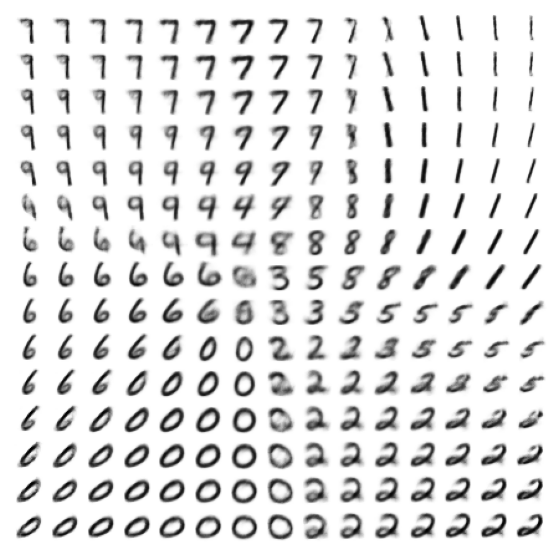

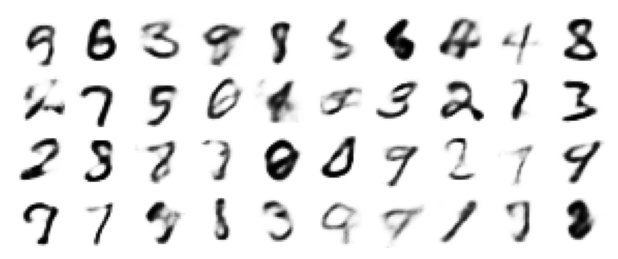

In [15]:
g = np.linspace(-2.5, 2.5, 15)
zg = jnp.asarray([[a, b] for b in g[::-1] for a in g], dtype=jnp.float32)
show_grid(np.asarray(vae_dec(vae2, zg)), 15, 15, "gen_vae_grid.png", size=0.42)
z_new = jax.random.normal(jax.random.key(11), (10000, 16))
vae16_samples = in_chunks(lambda z: vae_dec(vae16, z), z_new)
show_grid(vae16_samples[:40], 4, 10, "gen_vae_samples.png", size=0.7)

### Distance to the training set

A generator that merely reproduced training images would also produce convincing digits, so we check for copying. For each generated image we compute the Euclidean distance to the nearest of the 60 000 training images, $\min_i\lVert\hat{\mathbf x}-\mathbf x_i\rVert$, and compare it with the same distance for real test digits, which the network never saw.

In [16]:
@jax.jit
def nn_dist(A, B):            # distance of every row of A to its nearest row of B
    d2 = (A ** 2).sum(1)[:, None] - 2 * A @ B.T + (B ** 2).sum(1)[None, :]
    return jnp.sqrt(jnp.maximum(d2.min(1), 0))
d_gen = np.asarray(nn_dist(jnp.asarray(vae16_samples[:500]), Xtr_d))
d_test = np.asarray(nn_dist(Xte_d[:500], Xtr_d))
nums["vae_nn_dist_generated"], nums["vae_nn_dist_test"] = float(d_gen.mean()), float(d_test.mean())
print(f"mean distance to the nearest training image: generated {d_gen.mean():.2f}, real test digits {d_test.mean():.2f}")

mean distance to the nearest training image: generated 4.48, real test digits 4.19


The generated digits lie on average at distance 4.48 from the nearest training image, real unseen test digits at 4.19: the generated digits are no closer to the training set than real new digits, so the VAE does not copy. They are blurrier than real digits, because we show the pixel probabilities, an average over the Bernoulli pixels, and the ELBO rewards placing probability on all plausible images.

### Interpolation between two digits

A well-shaped latent space should also connect digits smoothly. We encode two test digits, $\boldsymbol\mu_a=\boldsymbol\mu_\phi(\mathbf x_a)$ and $\boldsymbol\mu_b=\boldsymbol\mu_\phi(\mathbf x_b)$, and decode the straight line $\mathbf z(t)=(1-t)\boldsymbol\mu_a+t\boldsymbol\mu_b$, $t\in[0,1]$. For comparison, the last row cross-fades the pixels, $(1-t)\mathbf x_a+t\mathbf x_b$, for the first pair.

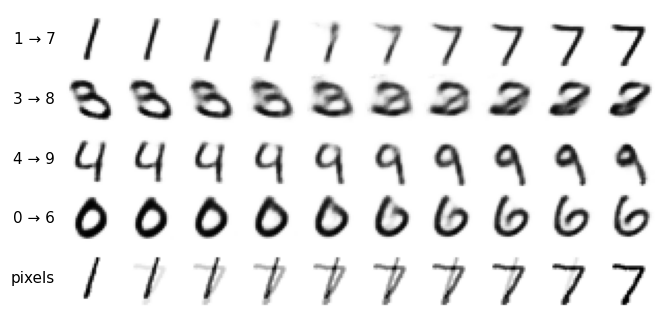

In [17]:
def first_of(digit, k=0): return int(np.flatnonzero(yte == digit)[k])
pairs = [(first_of(1), first_of(7)), (first_of(3), first_of(8)), (first_of(4), first_of(9)), (first_of(0), first_of(6))]
ts = np.linspace(0, 1, 10)[:, None]
rows = []
for a, b in pairs:
    mu_ab, _ = vae_enc(vae16, Xte_d[jnp.array([a, b])])
    rows.append(np.asarray(vae_dec(vae16, (1 - ts) * mu_ab[0] + ts * mu_ab[1])))
a, b = pairs[0]
rows.append((1 - ts) * Xte[a] + ts * Xte[b])
labels = [f"{yte[a]} → {yte[b]}" for a, b in pairs] + ["pixels"]
show_grid(np.concatenate(rows), len(rows), 10, "gen_vae_interp.png", size=0.7, row_labels=labels, fontsize=10)

Every point of the latent line decodes to a plausible digit: a 1 is bent into a 7, a 4 is closed into a 9. The pixel cross-fade passes through images that are two superposed digits, no digit at all. **The latent space is a coordinate system in which straight lines stay among the data.**

### Meaning of the latent coordinates

Two properties of the $d=16$ coordinates are of interest: which of them are used at all, and what each one does to the image. The first is measured by the KL term of coordinate $k$ averaged over the test images,
$$\overline{\mathrm{KL}}_k=\big\langle\tfrac12(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1)\big\rangle_{\mathbf x},$$
which gives, in nats, how much coordinate $k$ is used to describe the image. A value $\overline{\mathrm{KL}}_k\approx0$ would mean $q(z_k|\mathbf x)=\mathcal N(0,1)$ for every image, a coordinate ignored by the decoder; coordinates with $\overline{\mathrm{KL}}_k>0.1$ nats are called active. The second property is shown by latent traversals: we start from the encoding $\boldsymbol\mu_\phi(\mathbf x)$ of one test digit, change one coordinate $z_k$ from $-3$ to $3$ while keeping the others, and decode.

KL per latent coordinate, sorted (nats): [2.23 2.15 2.14 1.71 1.7  1.53 1.49 1.48 1.36 1.32 1.15 1.12 1.   0.98
 0.68 0.65]
coordinates with KL > 0.1 nats: 16 of 16


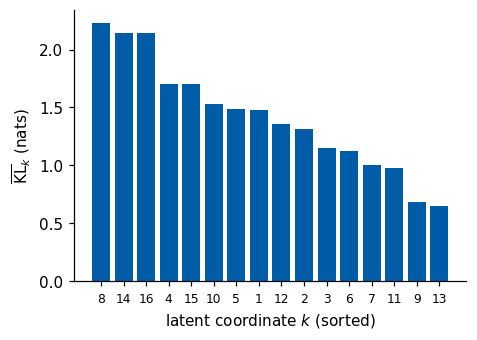

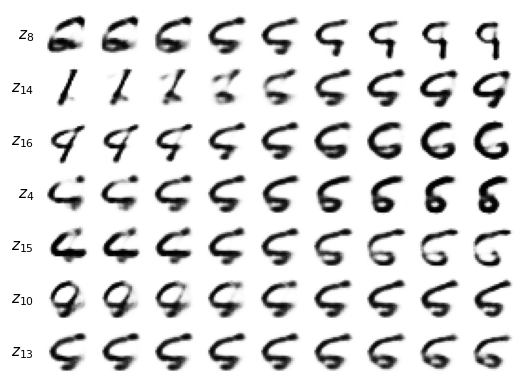

In [18]:
mu16_te, lv16_te = in_chunks(lambda x: vae_enc(vae16, x), Xte_d)
kl_dims = np.asarray(kl_per_dim(mu16_te, lv16_te)).mean(0)
order = np.argsort(kl_dims)[::-1]
nums["vae16_kl_per_dim_sorted"] = [float(v) for v in kl_dims[order]]
nums["vae16_active_dims"] = int((kl_dims > 0.1).sum())
print("KL per latent coordinate, sorted (nats):", np.round(kl_dims[order], 2))
print("coordinates with KL > 0.1 nats:", nums["vae16_active_dims"], "of 16")

fig, ax = plt.subplots(figsize=(4.6, 3.2))
ax.bar(np.arange(16), kl_dims[order], color=UJBlue)
ax.set_xticks(np.arange(16)); ax.set_xticklabels([str(k + 1) for k in order], fontsize=8)
ax.set_xlabel("latent coordinate $k$ (sorted)"); ax.set_ylabel(r"$\overline{\mathrm{KL}}_k$ (nats)")
save(fig, "gen_vae_kl_dims.png"); plt.show()

k_base = first_of(5)
mu_base = np.asarray(mu16_te[k_base])
vals = np.linspace(-3, 3, 9)
show_dims = list(order[:6]) + [order[-1]]
rows = []
for k in show_dims:
    Zt = np.repeat(mu_base[None], len(vals), 0); Zt[:, k] = vals
    rows.append(np.asarray(vae_dec(vae16, jnp.asarray(Zt))))
labels = [f"$z_{{{k + 1}}}$" for k in show_dims]          # top 6 by KL, and the least used coordinate
show_grid(np.concatenate(rows), len(rows), len(vals), "gen_vae_traversal.png", size=0.62, row_labels=labels, fontsize=10)
nums["traversal_dims"] = [int(k + 1) for k in show_dims]

The bar chart shows that all 16 coordinates carry information, but unequally: the largest $\overline{\mathrm{KL}}_k$, 2.23 nats, is more than three times the smallest, 0.65 nats. The traversals show that along a coordinate the digit changes continuously, in slant, width, thickness, and often in the identity of the digit too (top rows), while the least used coordinate (last row) changes the image only slightly.

A single coordinate is, however, in general *not* a single property of the digit. The prior $\mathcal N(0,I)$ and the KL term are unchanged by any rotation $\mathbf z\to R\mathbf z$, and the decoder can absorb the rotation, $G'(\mathbf z)=G(R^\top\mathbf z)$, so the loss does not fix the meaning of an axis. Without labels or further assumptions, "disentangled" coordinates (one property per axis) cannot be guaranteed: F. Locatello *et al.*, *Challenging Common Assumptions in the Unsupervised Learning of Disentangled Representations*, ICML 2019, [PMLR 97, 4114](https://proceedings.mlr.press/v97/locatello19a.html). The conditional VAE of Section 6 is one way out: we tell the model *what* to draw.

Exercises:

1. Train VAEs with $d=32$ and $d=64$ and plot $\overline{\mathrm{KL}}_k$. Do all coordinates stay in use?
2. Train the $d=16$ VAE without the KL term (loss = reconstruction only) and generate from $\mathcal N(0,I)$ again. What happens, and why? Then multiply the KL term by $\beta=4$: what happens to the number of active dimensions and to the sharpness of the samples?

<hr/>
## 5. Judging generated digits with a classifier

So far the generated images have been judged by eye. To **measure** what a generator produces we need a referee: a classifier trained on the **real** data, whose accuracy on real test data we know. We then apply it, unchanged, to synthetic images.

The classifier is a small CNN: two convolutions ($3\times3$, 16 and 32 channels, ReLU), each followed by $2\times2$ max-pooling ($28\to14\to7$), a dense layer of 128 units and 10 outputs $f_c(\mathbf x)$. It is trained by minimising the cross-entropy
$$\mathcal L=-\frac1n\sum_{i}\log p(y_i|\mathbf x_i),\qquad p(c|\mathbf x)=\frac{e^{f_c(\mathbf x)}}{\sum_{c'}e^{f_{c'}(\mathbf x)}},$$
which is the negative log-likelihood of the labels (Section 2).

A convolution is a dense layer applied to every patch of the image. A $3\times3$ convolution with $C_{\rm in}$ input and $C_{\rm out}$ output channels computes, at every pixel, the same linear map of the $9C_{\rm in}$ numbers in the $3\times3$ neighbourhood, plus a bias. The implementation follows this description literally: `patches3x3` collects the neighbourhoods, $(B,H,W,C_{\rm in})\to(B,H,W,9C_{\rm in})$, and an ordinary `nnx.Linear(9 C_in, C_out)` acts on the last axis. This "im2col" form turns the convolution into one large matrix product, which on a CPU runs several times faster than a direct convolution for these small filters. The weights are shared over all positions, exactly as in a convolution.

For a minibatch of $B$ images the shapes are $(B,784)\to$ reshape $(B,28,28,1)\to$ patches $(B,28,28,9)\to$ conv $(B,28,28,16)\to$ pool $(B,14,14,16)\to$ patches $(B,14,14,144)\to$ conv $(B,14,14,32)\to$ pool $(B,7,7,32)\to$ flatten $(B,1568)\to(B,128)\to$ logits $(B,10)$. Zero padding at the border (`"SAME"`) keeps the image size. Max-pooling over $2\times2$ blocks is a reshape: the axis of length 28 is split into $(14,2)$, and the maximum is taken over the axes of length 2. After four epochs the classifier reaches an accuracy of 0.9854 on the 10 000 real test digits, which sets the baseline for everything that follows.

In [19]:
def patches3x3(h):
    """All 3x3 neighbourhoods of every pixel (zero padding at the border).
    (B, H, W, C) -> (B, H, W, 9 C): the 9 C numbers a 3x3 filter sees at each position."""
    return jax.lax.conv_general_dilated_patches(h, filter_shape=(3, 3), window_strides=(1, 1), padding="SAME",
                                                dimension_numbers=("NHWC", "HWIO", "NHWC"))

def maxpool2x2(h):
    """(B, H, W, C) -> (B, H/2, W/2, C): maximum over non-overlapping 2x2 blocks."""
    B, H, W, C = h.shape
    return h.reshape(B, H // 2, 2, W // 2, 2, C).max(axis=(2, 4))

class CNN(nnx.Module):
    """conv(3x3, 16) - ReLU - pool - conv(3x3, 32) - ReLU - pool - dense 128 - ReLU - dense 10."""
    def __init__(self, *, rngs):
        self.conv1 = nnx.Linear(9 * 1, 16, rngs=rngs)       # a 3x3 convolution = one dense layer applied to every 3x3 patch
        self.conv2 = nnx.Linear(9 * 16, 32, rngs=rngs)
        self.f1, self.f2 = nnx.Linear(7 * 7 * 32, 128, rngs=rngs), nnx.Linear(128, 10, rngs=rngs)
    def __call__(self, x):                                   # x: (B, 784) -> logits (B, 10)
        B = x.shape[0]
        h = x.reshape(B, 28, 28, 1)                          # layout (batch, height, width, channels)
        h = maxpool2x2(nnx.relu(self.conv1(patches3x3(h))))  # (B, 28, 28, 9) -> (B, 28, 28, 16) -> (B, 14, 14, 16)
        h = maxpool2x2(nnx.relu(self.conv2(patches3x3(h))))  # (B, 14, 14, 144) -> (B, 14, 14, 32) -> (B, 7, 7, 32)
        return self.f2(nnx.relu(self.f1(h.reshape(B, -1))))  # (B, 1568) -> (B, 128) -> (B, 10)

def clf_loss(model, batch, key):
    x, y = batch
    logits = model(x)
    loss = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return loss, {"loss": loss, "acc": jnp.mean(logits.argmax(-1) == y)}

assert patches3x3(jnp.zeros((2, 28, 28, 1))).shape == (2, 28, 28, 9)
assert CNN(rngs=nnx.Rngs(0))(Xtr_d[:3]).shape == (3, 10)
print("CNN classifier"); clf, _ = train(CNN(rngs=nnx.Rngs(5)), clf_loss, (Xtr_d, ytr_d), epochs=4, seed=5, batch_size=256, log_every=1)
clf_prob = nnx.jit(lambda m, x: jax.nn.softmax(m(x)))
def classify(X):
    """Probabilities p(c | x) of the classifier for every image."""
    return in_chunks(lambda x: clf_prob(clf, x), jnp.asarray(X))
P_test = classify(Xte)
nums["clf_test_acc"] = float((P_test.argmax(1) == yte).mean())
print(f"classifier accuracy on the 10 000 real test digits: {nums['clf_test_acc']:.4f}")

CNN classifier


  epoch   1: acc 0.9096  loss 0.3065   ( 29.8 s)


  epoch   2: acc 0.9749  loss 0.0825   ( 58.5 s)


  epoch   3: acc 0.9825  loss 0.0573   ( 87.0 s)


  epoch   4: acc 0.9862  loss 0.0449   (115.0 s)


classifier accuracy on the 10 000 real test digits: 0.9854


### Confusion matrices: real digits and their VAE reconstructions

A confusion matrix has one **row per true digit $a$** and one **column per digit $b$ assigned by the classifier**:
$$C_{ab}=\frac{\#\{\text{images of digit }a\text{ assigned to }b\}}{\#\{\text{images of digit }a\}},\qquad\sum_bC_{ab}=1 .$$
A perfect generator-plus-classifier gives the identity matrix. An unconditional VAE is not told which digit to draw, so we take the digit from its input: each real test digit $\mathbf x$ of label $a$ is encoded, one $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$ is drawn, and the classifier labels the decoded image $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$. The real test images (left panel) are the baseline: the matrix of the classifier itself.

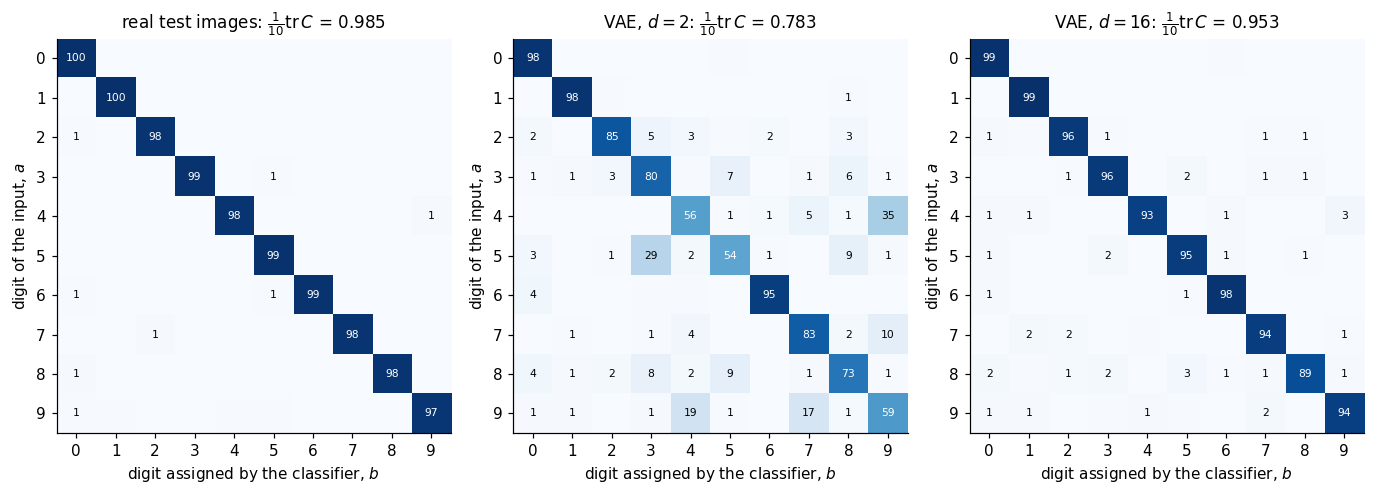

{'real': 0.9853495819132055, 'vae2': 0.7826667783222012, 'vae16': 0.9532889271611754}
largest off-diagonal entry, d = 2: 4 -> 9: 0.346


In [20]:
def vae_recon_sample(model, X, key):
    mu, lv = in_chunks(lambda x: vae_enc(model, x), jnp.asarray(X))
    z = mu + np.exp(0.5 * lv) * np.asarray(jax.random.normal(key, mu.shape))
    return in_chunks(lambda z: vae_dec(model, z), jnp.asarray(z))

def confusion(true, pred):
    """C[a, b] = fraction of the samples with row label a (true or requested digit) that the classifier assigns to b."""
    C = np.zeros((10, 10))
    np.add.at(C, (true, pred), 1)
    return C / C.sum(1, keepdims=True)

rec2 = vae_recon_sample(vae2, Xte, jax.random.key(20))
rec16 = vae_recon_sample(vae16, Xte, jax.random.key(21))
mats = {"real test images": confusion(yte, P_test.argmax(1)),
        "VAE, $d=2$": confusion(yte, classify(rec2).argmax(1)),
        "VAE, $d=16$": confusion(yte, classify(rec16).argmax(1))}
fig, axs = plt.subplots(1, 3, figsize=(12.6, 4.3))
for a, (name, C) in zip(axs, mats.items()):
    a.imshow(C, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if round(100 * C[i, j]) >= 1:                              # print entries of at least 1 %
                a.text(j, i, f"{100 * C[i, j]:.0f}", ha="center", va="center", fontsize=7,
                       color="white" if C[i, j] > 0.5 else "black")
    a.set_xticks(range(10)); a.set_yticks(range(10))
    a.set_xlabel("digit assigned by the classifier, $b$"); a.set_ylabel("digit of the input, $a$")
    a.set_title(f"{name}: " + r"$\frac{1}{10}\mathrm{tr}\,C$" + f" = {np.trace(C) / 10:.3f}")
plt.tight_layout(); save(fig, "gen_vae_confusion.png"); plt.show()
nums["confusion_diag_mean"] = {"real": float(np.trace(mats["real test images"]) / 10),
                               "vae2": float(np.trace(mats["VAE, $d=2$"]) / 10),
                               "vae16": float(np.trace(mats["VAE, $d=16$"]) / 10)}
C2 = mats["VAE, $d=2$"].copy(); np.fill_diagonal(C2, 0)
i, j = np.unravel_index(np.argmax(C2), C2.shape)
nums["vae2_worst_confusion"] = [int(i), int(j), float(C2[i, j])]
print(nums["confusion_diag_mean"]); print(f"largest off-diagonal entry, d = 2: {i} -> {j}: {C2[i, j]:.3f}")

With $d=16$ the decoded digits keep their identity almost as often as the classifier recognises the real images (mean diagonal 0.953 against 0.985). With $d=2$ the latent plane is too small (mean diagonal 0.783): digits that look alike, such as 4 and 9 or 3, 5 and 8, share a region of the plane, and the decoder produces the wrong one; the worst case is a 4 classified as a 9 in 35% of the reconstructions.

### Digit distribution of the generated samples

Now the images are decoded from the prior, $\mathbf z\sim\mathcal N(0,I)$, with no input digit, which is how the VAE is used as a generator. We measure two things. The first is the **class distribution** of 10 000 generated digits, $f_b=\#\{\text{samples assigned to }b\}/N$, which we compare with the fraction of each digit in the training set; a missing class would show up here. The second is the **confidence** of the classifier, $\max_c p(c|\hat{\mathbf x})$. We report the fraction of images with confidence above 0.9 and compare it between real test digits, VAE samples, and the random decodings of the autoencoder of Section 1 (for $d=2$ uniform on the grid box, for $d=16$ $z_k\sim\mathcal N(m_k,s_k^2)$).

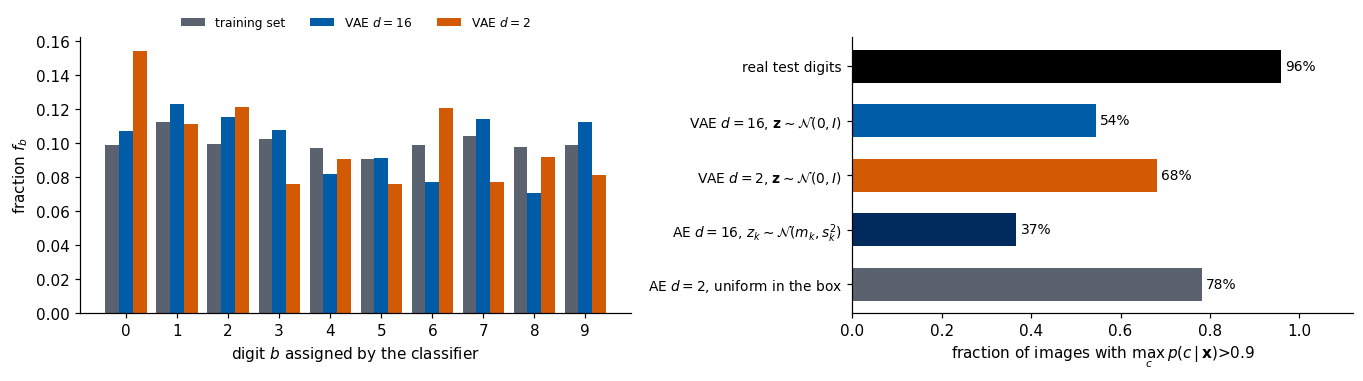

real_test                                     confident (> 0.9): 0.959
vae16_prior                                   confident (> 0.9): 0.545
vae2_prior                                    confident (> 0.9): 0.680
ae16_fitted_gauss                             confident (> 0.9): 0.367
ae2_box                                       confident (> 0.9): 0.781
class fractions, training set:           [0.099 0.112 0.099 0.102 0.097 0.09  0.099 0.104 0.098 0.099]
class fractions, VAE d = 16:             [0.107 0.123 0.115 0.107 0.082 0.091 0.077 0.114 0.071 0.112]
class fractions, VAE d = 2:              [0.154 0.111 0.122 0.076 0.09  0.076 0.121 0.077 0.092 0.081]
class fractions, AE d = 2, uniform box:  [0.052 0.476 0.028 0.004 0.011 0.072 0.202 0.117 0.004 0.034]


In [21]:
z2_new = jax.random.normal(jax.random.key(12), (10000, 2))
vae2_samples = in_chunks(lambda z: vae_dec(vae2, z), z2_new)
z_box = lo + (hi - lo) * np.asarray(jax.random.uniform(jax.random.key(13), (2000, 2)))
ae2_box_samples = np.asarray(ae_decode(ae2, jnp.asarray(z_box, dtype=jnp.float32)))

P_vae16, P_vae2 = classify(vae16_samples), classify(vae2_samples)
P_ae16, P_ae2 = classify(imgs_ae16_fit), classify(ae2_box_samples)
f_train = np.bincount(ytr, minlength=10) / len(ytr)
f16, f2 = np.bincount(P_vae16.argmax(1), minlength=10) / len(P_vae16), np.bincount(P_vae2.argmax(1), minlength=10) / len(P_vae2)
nums["class_frac_train"], nums["class_frac_vae16"], nums["class_frac_vae2"] = f_train.tolist(), f16.tolist(), f2.tolist()

conf_sets = [("real_test", "real test digits", P_test),
             ("vae16_prior", "VAE $d=16$, $\\mathbf{z}\\sim\\mathcal{N}(0,I)$", P_vae16),
             ("vae2_prior", "VAE $d=2$, $\\mathbf{z}\\sim\\mathcal{N}(0,I)$", P_vae2),
             ("ae16_fitted_gauss", "AE $d=16$, $z_k\\sim\\mathcal{N}(m_k,s_k^2)$", P_ae16),
             ("ae2_box", "AE $d=2$, uniform in the box", P_ae2)]
nums["frac_confident_0.9"] = {}
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.6), gridspec_kw=dict(width_ratios=[1.1, 1]))
w = 0.27
axs[0].bar(np.arange(10) - w, f_train, w, color=UJGray, label="training set")
axs[0].bar(np.arange(10), f16, w, color=UJBlue, label="VAE $d=16$")
axs[0].bar(np.arange(10) + w, f2, w, color=DSOrange, label="VAE $d=2$")
axs[0].set_xticks(range(10)); axs[0].set_xlabel("digit $b$ assigned by the classifier"); axs[0].set_ylabel("fraction $f_b$")
axs[0].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.12))
for (key, name, P) in conf_sets:
    nums["frac_confident_0.9"][key] = float((P.max(1) > 0.9).mean())   # fraction of images with max_c p(c|x) > 0.9
fr = [nums["frac_confident_0.9"][k] for k, _, _ in conf_sets]
ypos = np.arange(len(conf_sets))[::-1]
axs[1].barh(ypos, fr, color=["k", UJBlue, DSOrange, UJNavy, UJGray], height=0.6)
for yy_, f_ in zip(ypos, fr): axs[1].text(f_ + 0.01, yy_, f"{100 * f_:.0f}%", va="center", fontsize=9)
axs[1].set_yticks(ypos); axs[1].set_yticklabels([n for _, n, _ in conf_sets], fontsize=9)
axs[1].set_xlim(0, 1.12); axs[1].set_xlabel(r"fraction of images with $\max_c\, p(c\,|\,\mathbf{x}) > 0.9$")
plt.tight_layout(); save(fig, "gen_vae_class_dist.png"); plt.show()
for k, v in nums["frac_confident_0.9"].items(): print(f"{k:45s} confident (> 0.9): {v:.3f}")
f_ae2_box = np.bincount(P_ae2.argmax(1), minlength=10) / len(P_ae2)
nums["class_frac_ae2_box"] = f_ae2_box.tolist()
print("class fractions, training set:          ", np.round(f_train, 3))
print("class fractions, VAE d = 16:            ", np.round(f16, 3))
print("class fractions, VAE d = 2:             ", np.round(f2, 3))
print("class fractions, AE d = 2, uniform box: ", np.round(f_ae2_box, 3))

The $d=16$ VAE produces every digit with roughly the frequency of the training set: no class is missing (no *mode collapse*). The $d=2$ VAE over-produces 0s (15.4%) and under-produces 3s, 5s and 7s (about 7.6% each): in two dimensions the digits are crowded, and the prior does not give each the same area. The classifier is confident about real digits (95.9% above 0.9) far more often than about VAE samples (54.5% for $d=16$), because many samples are blurry or lie between two digits. The $d=16$ autoencoder decoded from a fitted Gaussian is the worst case, at 36.7%. The $d=2$ autoencoder sampled uniformly over its box scores high, 78.1%: in two dimensions its decoder produces digit-like images almost everywhere. Uniform sampling of the box is nevertheless not a model of the data: it over-produces the digits whose codes are spread over a large area of the plane (47.6% are 1s, see the printed class fractions), and it has no probability distribution attached.

As an exercise, sort the 10 000 VAE samples by the classifier confidence and show the 20 least confident ones. Identify the pairs of digits they lie between, and compare with the largest off-diagonal entries of the confusion matrix.

<hr/>
## 6. The conditional VAE

A VAE draws *some* digit. Often we want to choose *what* to generate: the digit 7, or, in physics, a spin configuration at temperature $T$. If a label $\mathbf c$ is known for every training image, it can be given to both networks as an extra input [K. Sohn, H. Lee, X. Yan, *Learning Structured Output Representation using Deep Conditional Generative Models*, NeurIPS 2015, [proceedings](https://papers.nips.cc/paper_files/paper/2015/hash/8d55a249e6baa5c06772297520da2051-Abstract.html)]. The encoder becomes $q_\phi(\mathbf z|\mathbf x,\mathbf c)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x,\mathbf c),\mathrm{diag}\,\boldsymbol\sigma^2_\phi(\mathbf x,\mathbf c)\big)$, whose input is the concatenation $[\mathbf x,\mathbf c]\in\mathbb R^{784+10}$, and the decoder becomes $p_\theta(\mathbf x|\mathbf z,\mathbf c)$, whose input is $[\mathbf z,\mathbf c]\in\mathbb R^{d+10}$. The prior stays $p(\mathbf z)=\mathcal N(0,I)$, the same for every $\mathbf c$. Generation then means choosing $\mathbf c$, drawing $\mathbf z\sim\mathcal N(0,I)$ and decoding $\sigma(G_\theta(\mathbf z,\mathbf c))$.

The model is now a model of the *conditional* distribution,
$$p_\theta(\mathbf x|\mathbf c)=\int p_\theta(\mathbf x|\mathbf z,\mathbf c)\,p(\mathbf z)\,d\mathbf z ,$$
and the derivation of Section 3.2 goes through with $\mathbf c$ carried along as a fixed parameter. Bayes' rule at fixed $\mathbf c$ reads $p_\theta(\mathbf x|\mathbf c)=p_\theta(\mathbf x|\mathbf z,\mathbf c)p(\mathbf z)/p_\theta(\mathbf z|\mathbf x,\mathbf c)$; taking the logarithm, inserting $q_\phi(\mathbf z|\mathbf x,\mathbf c)$ and averaging over it gives the conditioned ELBO,
$$\log p_\theta(\mathbf x|\mathbf c)=\underbrace{\mathbb E_{q_\phi(\mathbf z|\mathbf x,\mathbf c)}\big[\log p_\theta(\mathbf x|\mathbf z,\mathbf c)\big]-\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x,\mathbf c)\,\|\,p(\mathbf z)\big)}_{\mathrm{ELBO}(\theta,\phi;\,\mathbf x,\mathbf c)}+\underbrace{\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x,\mathbf c)\,\|\,p_\theta(\mathbf z|\mathbf x,\mathbf c)\big)}_{\ge 0}.$$
The loss is again BCE plus the closed-form KL divergence, now computed from $(\boldsymbol\mu,\log\boldsymbol\sigma^2)=$ encoder$([\mathbf x,\mathbf c])$ and logits $=$ decoder$([\mathbf z,\mathbf c])$, and the training data are pairs $(\mathbf x_i,\mathbf c_i)$. Sohn *et al.* also allow a learned, $\mathbf c$-dependent prior $p_\theta(\mathbf z|\mathbf c)$; the fixed $\mathcal N(0,I)$ used here is the simplest choice and lets us sample $\mathbf z$ the same way for every $\mathbf c$.

The shapes are $\mathbf x$: $(B,784)$; $\mathbf c$: $(B,10)$; encoder input $[\mathbf x,\mathbf c]$: $(B,794)$; $\boldsymbol\mu,\log\boldsymbol\sigma^2,\mathbf z$: $(B,d)$; decoder input $[\mathbf z,\mathbf c]$: $(B,d+10)$; logits: $(B,784)$.

Here $\mathbf c$ is the **one-hot** vector of the digit, $c_j=\delta_{j,y}$. A single number $y\in\{0,\dots,9\}$ would impose an order and a distance on the classes, as if 3 were between 2 and 4. Since $\mathbf c$ already tells the decoder *which* digit to draw, the KL term pushes $\mathbf z$ to carry only what $\mathbf c$ does not say: the **style** of the handwriting.

The `VAE` class of Section 3 already supports all this: `VAE(d, cond=10)` provides `model.encode(x, c)` and `model.decode(z, c)`, and `vae_loss` receives the minibatch `(x, c)`. We train a cVAE with $d=8$ (20 epochs) and, to draw its latent plane, one with $d=2$ (10 epochs).

In [22]:
_m = VAE(8, cond=10, rngs=nnx.Rngs(0))
_mu, _lv = _m.encode(Xtr_d[:5], Ctr_d[:5])
assert Ctr_d.shape == (60000, 10) and _mu.shape == (5, 8)
assert _m.decode(_mu, Ctr_d[:5]).shape == (5, 784)
print("one-hot condition of the first training image (label", int(ytr[0]), "):", np.asarray(Ctr_d[0]).astype(int))

t0 = time.time()
print("cVAE, d = 8"); cvae, h_cvae = train(VAE(8, cond=10, rngs=nnx.Rngs(6)), vae_loss, (Xtr_d, Ctr_d), epochs=EPOCHS_VAE, seed=6)
print("cVAE, d = 2"); cvae2, _ = train(VAE(2, cond=10, rngs=nnx.Rngs(7)), vae_loss, (Xtr_d, Ctr_d), epochs=10, seed=7)
nums["cvae_train_seconds"] = time.time() - t0
Cte_d = jax.nn.one_hot(jnp.asarray(yte), 10)
_, aux = nnx.jit(vae_loss)(cvae, (Xte_d, Cte_d), jax.random.key(8))
nums["cvae8_test"] = {k: float(v) for k, v in aux.items()}
print("cVAE d = 8, test, per image:", {k: round(v, 1) for k, v in nums["cvae8_test"].items()})
cvae_enc = nnx.jit(lambda m, x, c: m.encode(x, c))
cvae_dec = nnx.jit(lambda m, z, c: jax.nn.sigmoid(m.decode(z, c)))

one-hot condition of the first training image (label 5 ): [0 0 0 0 0 1 0 0 0 0]
cVAE, d = 8


  epoch   1: kl 10.1073  loss 152.5285  rec 142.4211   (  6.7 s)


  epoch   5: kl 13.7887  loss 108.4267  rec 94.6380   ( 27.0 s)


  epoch  10: kl 13.9472  loss 103.0818  rec 89.1346   ( 52.5 s)


  epoch  15: kl 14.0492  loss 100.4567  rec 86.4075   ( 78.3 s)


  epoch  20: kl 14.1569  loss 98.8509  rec 84.6939   (103.5 s)
cVAE, d = 2


  epoch   1: kl 3.9791  loss 166.1013  rec 162.1222   (  6.6 s)


  epoch   5: kl 4.6543  loss 132.9477  rec 128.2934   ( 26.6 s)


  epoch  10: kl 4.8239  loss 129.8814  rec 125.0575   ( 51.4 s)


cVAE d = 8, test, per image: {'kl': 14.3, 'loss': 99.6, 'rec': 85.3}


### Digits on demand

The first test of the cVAE is whether the condition and the latent vector play the roles we intended. Each row of the figure uses one condition $\mathbf c$, the digits 0 to 9. Each column uses one random $\mathbf z\sim\mathcal N(0,I)$, the **same** in every row.

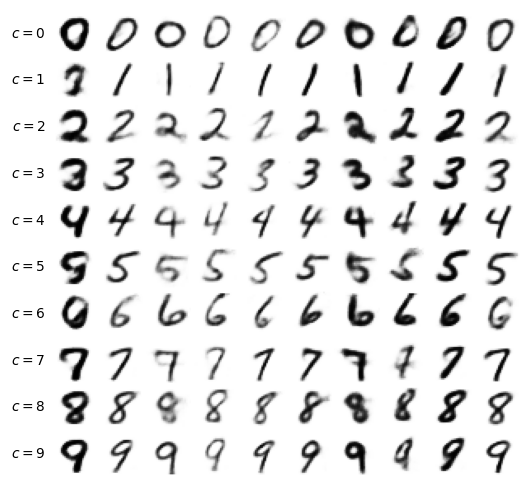

In [23]:
zc = jax.random.normal(jax.random.key(14), (10, 8))
rows = [np.asarray(cvae_dec(cvae, zc, jax.nn.one_hot(jnp.full(10, dgt), 10))) for dgt in range(10)]
show_grid(np.concatenate(rows), 10, 10, "gen_cvae_mnist.png", size=0.55,
          row_labels=[f"$c={d}$" for d in range(10)], fontsize=9)

Along a column the digit changes and the style stays: slant, stroke width and size are carried by $\mathbf z$, the identity by $\mathbf c$.

### Style transfer

The same separation lets us transfer the handwriting of a real digit to other digits. We encode a real test digit with its own label, $\boldsymbol\mu=\boldsymbol\mu_\phi(\mathbf x,\mathbf c_y)$, then decode this one $\mathbf z=\boldsymbol\mu$ with every condition $\mathbf c=0,\dots,9$: the same handwriting, all ten digits.

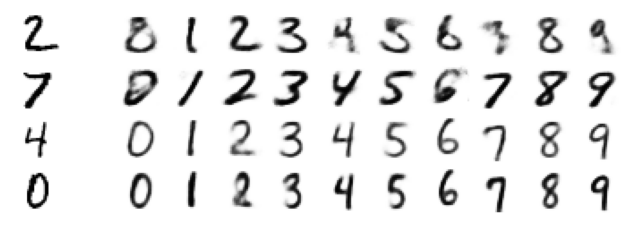

In [24]:
picks = [first_of(2), first_of(7, 3), first_of(4, 2), first_of(0, 5)]
rows = []
for k in picks:
    mu, _ = cvae_enc(cvae, Xte_d[k:k + 1], Cte_d[k:k + 1])
    out = np.asarray(cvae_dec(cvae, jnp.repeat(mu, 10, 0), jnp.eye(10)))
    rows.append(np.concatenate([Xte[k:k + 1], np.ones((1, 784)) * 0, out]))
show_grid(np.concatenate(rows), len(picks), 12, "gen_cvae_style.png", size=0.6)

### The latent plane of a cVAE

If $\mathbf z$ really carries only style, the digit identity should no longer be visible in the latent plane. We repeat the test of Section 4 for a cVAE with $d=2$: the right panel shows the means $\boldsymbol\mu_\phi(\mathbf x,\mathbf c)$ of the test digits, coloured by the digit, and the left panel the VAE with $d=2$ for comparison. A simple number quantifies the difference: we predict the digit from the nearest class mean in the latent plane and report how often this prediction is correct.

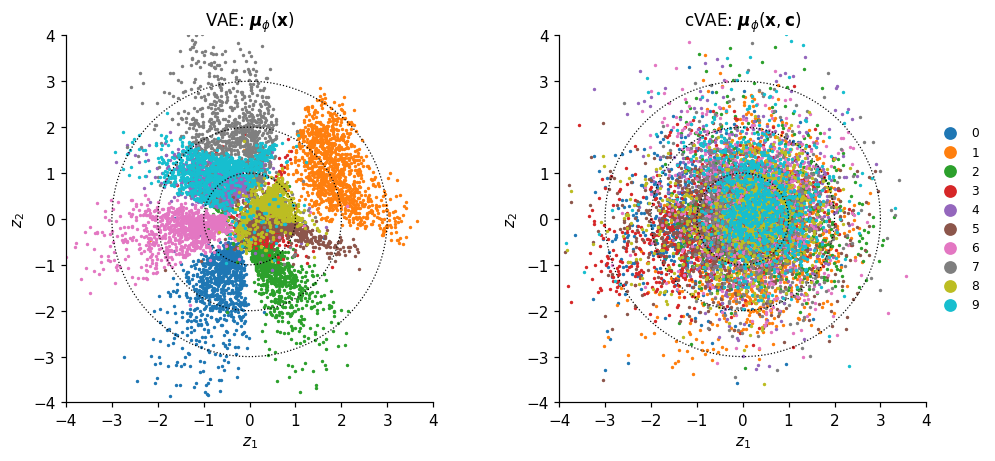

digit predicted from the nearest class mean in the latent plane: VAE 0.732, cVAE 0.180 (chance 0.1)


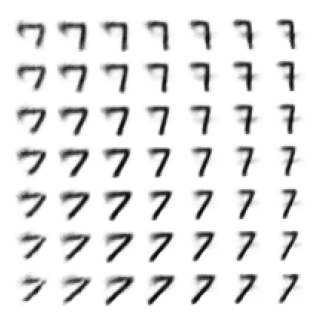

In [25]:
mu_c2 = in_chunks(lambda x, c: cvae_enc(cvae2, x, c)[0], Xte_d, Cte_d)
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.3))
for a, Z, title in [(axs[0], mu2_te, "VAE: $\\boldsymbol{\\mu}_\\phi(\\mathbf{x})$"),
                    (axs[1], mu_c2, "cVAE: $\\boldsymbol{\\mu}_\\phi(\\mathbf{x}, \\mathbf{c})$")]:
    for d in range(10):
        m = yte == d
        a.scatter(Z[m, 0], Z[m, 1], s=1.5, color=cmap10(d), label=str(d), rasterized=True)
    for r in (1, 2, 3): a.plot(r * np.cos(t), r * np.sin(t), "k:", lw=0.8)
    a.set_aspect("equal"); a.set_xlim(-4, 4); a.set_ylim(-4, 4); a.set_xlabel("$z_1$"); a.set_ylabel("$z_2$"); a.set_title(title)
axs[1].legend(markerscale=6, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); save(fig, "gen_cvae_latent.png"); plt.show()

# how much does z tell about the digit? nearest-class-mean accuracy in the latent plane
def centroid_acc(Z, y):
    cent = np.stack([Z[y == d].mean(0) for d in range(10)])
    return float((((Z[:, None] - cent[None]) ** 2).sum(-1).argmin(1) == y).mean())
nums["latent_centroid_acc_vae2"], nums["latent_centroid_acc_cvae2"] = centroid_acc(mu2_te, yte), centroid_acc(mu_c2, yte)
print(f"digit predicted from the nearest class mean in the latent plane: VAE {nums['latent_centroid_acc_vae2']:.3f}, "
      f"cVAE {nums['latent_centroid_acc_cvae2']:.3f} (chance 0.1)")

zg2 = jnp.asarray([[a, b] for b in np.linspace(2, -2, 7) for a in np.linspace(-2, 2, 7)], dtype=jnp.float32)
show_grid(np.asarray(cvae_dec(cvae2, zg2, jax.nn.one_hot(jnp.full(49, 7), 10))), 7, 7, "gen_cvae2_grid7.png", size=0.5)

In the VAE the digits form separate regions of the plane, and the nearest class mean predicts the digit correctly in 73% of the cases. In the cVAE all digits share the same disc, and the position of a digit in the latent plane says little about which digit it is: the nearest-class-mean prediction is correct in 18% of the cases, close to the chance level of 10%. The latent plane of the cVAE is a map of style alone: decoding a grid of $\mathbf z$ with $\mathbf c=7$ gives sevens that differ in slant and width.

### Confusion matrix of requested digits

The classifier of Section 5 now tests whether the cVAE draws what we ask for. For every requested digit $a$ we generate 1000 images with $\mathbf z\sim\mathcal N(0,I)$ and $\mathbf c=$ one-hot$(a)$, and let the classifier label them. The confusion matrix now has one **row per requested digit $a$** and one **column per digit $b$ assigned by the classifier**,
$$C_{ab}=\frac{\#\{\text{samples generated with }\mathbf c=a\text{ assigned to }b\}}{1000}.$$

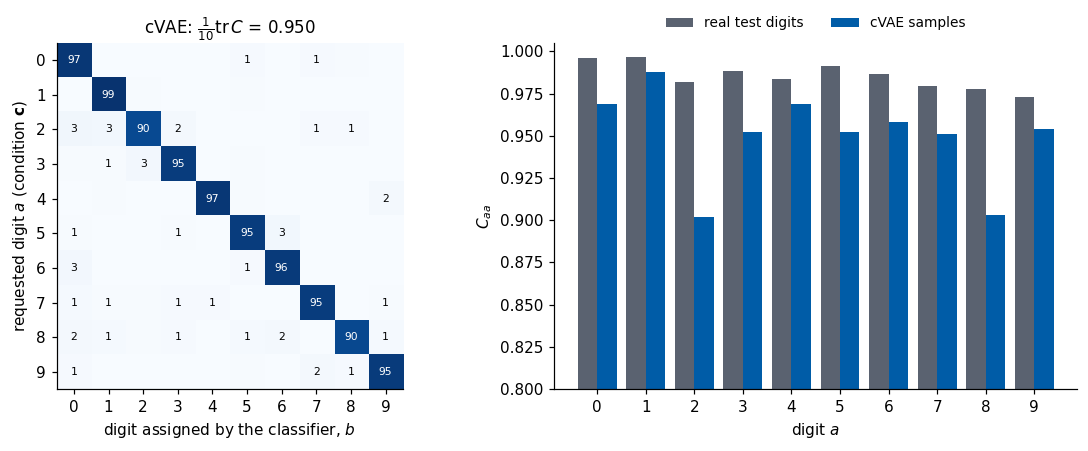

C_aa per requested digit: [0.969 0.988 0.902 0.952 0.969 0.952 0.958 0.951 0.903 0.954] | mean 0.9498
largest off-diagonal entry: requested 2, classified as 0: 0.032
fraction of cVAE samples with classifier confidence > 0.9: 0.875


In [26]:
N_PER = 1000
req = np.repeat(np.arange(10), N_PER)
z_req = jax.random.normal(jax.random.key(15), (10 * N_PER, 8))
cvae_samples = in_chunks(lambda z, c: cvae_dec(cvae, z, c), z_req, jax.nn.one_hot(jnp.asarray(req), 10))
P_cvae = classify(cvae_samples)
C_cvae = confusion(req, P_cvae.argmax(1))
nums["cvae_agreement_per_digit"] = np.diag(C_cvae).tolist()
nums["cvae_agreement_mean"] = float(np.trace(C_cvae) / 10)
nums["cvae_frac_confident_0.9"] = float((P_cvae.max(1) > 0.9).mean())
Cc = C_cvae.copy(); np.fill_diagonal(Cc, 0); i, j = np.unravel_index(np.argmax(Cc), Cc.shape)
nums["cvae_worst_confusion"] = [int(i), int(j), float(Cc[i, j])]

fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw=dict(width_ratios=[1, 1.05]))
a = axs[0]
a.imshow(C_cvae, cmap="Blues", vmin=0, vmax=1)
for i_ in range(10):
    for j_ in range(10):
        if round(100 * C_cvae[i_, j_]) >= 1:
            a.text(j_, i_, f"{100 * C_cvae[i_, j_]:.0f}", ha="center", va="center", fontsize=7,
                   color="white" if C_cvae[i_, j_] > 0.5 else "black")
a.set_xticks(range(10)); a.set_yticks(range(10))
a.set_xlabel("digit assigned by the classifier, $b$"); a.set_ylabel("requested digit $a$ (condition $\\mathbf{c}$)")
a.set_title(r"cVAE: $\frac{1}{10}\mathrm{tr}\,C$" + f" = {nums['cvae_agreement_mean']:.3f}")
axs[1].bar(np.arange(10) - 0.2, np.diag(mats["real test images"]), 0.4, color=UJGray, label="real test digits")
axs[1].bar(np.arange(10) + 0.2, np.diag(C_cvae), 0.4, color=UJBlue, label="cVAE samples")
axs[1].set_ylim(0.8, 1.005); axs[1].set_xticks(range(10)); axs[1].set_xlabel("digit $a$"); axs[1].set_ylabel("$C_{aa}$")
axs[1].legend(fontsize=9, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); save(fig, "gen_cvae_confusion.png"); plt.show()
print("C_aa per requested digit:", np.round(np.diag(C_cvae), 3), "| mean", round(nums["cvae_agreement_mean"], 4))
print(f"largest off-diagonal entry: requested {i}, classified as {j}: {Cc[i, j]:.3f}")
print(f"fraction of cVAE samples with classifier confidence > 0.9: {nums['cvae_frac_confident_0.9']:.3f}")

For every requested digit the large majority of the samples is classified as requested, by a classifier that never saw a synthetic image: the diagonal entries range from 0.902 (digit 2) to 0.988 (digit 1), with mean 0.950, and the largest confusion is a requested 2 classified as 0 in 3.2% of the samples. The same protocol carries over to physics in Lab 025. There the condition $\mathbf c$ is a temperature $T$ or a point $(g,T)$ of a phase diagram, samples are generated at a chosen $\mathbf c$, and the referees are networks trained on real Monte Carlo data, together with observables computed from the Hamiltonian itself.

Exercises:

1. Give the cVAE a *mixed* condition, $\mathbf c=\frac12(\mathbf e_4+\mathbf e_9)$, a vector it never saw in training. What does it draw, and what does the classifier say?
2. Replace the one-hot condition by the single number $c=y/9$. Does the cVAE still generate the requested digits? Measure it with the confusion matrix.

<hr/>
## From autoencoders to conditional generation

An autoencoder learns a latent space but not a distribution on it, which is why random latent vectors decode to non-digits. Maximum likelihood is the principle for fitting a distribution $p_\theta$ to data; for a latent-variable model $p_\theta(\mathbf x)=\int p_\theta(\mathbf x|\mathbf z)p(\mathbf z)d\mathbf z$ the likelihood cannot be computed, and the VAE maximises instead the lower bound $\mathrm{ELBO}=\mathbb E_q\log p_\theta(\mathbf x|\mathbf z)-\mathrm{KL}(q\,\|\,p)$, made trainable by the reparametrisation trick. The KL term shapes the latent space into the prior $\mathcal N(0,I)$, so that sampling, interpolation and traversals work, although individual axes need not have a meaning. A classifier trained on real data then serves as a referee for synthetic data through confusion matrices, class distributions and confidence. Finally, a conditional VAE adds a known label $\mathbf c$ to encoder and decoder: $\mathbf c$ selects *what* is generated, and $\mathbf z$ carries the rest. Lab 025 applies this machinery to spin configurations.